# Potential production (winter wheat)

This example runs torchcrop's **Lintul5** model in **potential production** mode
over nineteen winter-wheat growing seasons (1972-1990 sowing years) at West
Lafayette, Indiana, then plots the full state and diagnostic trajectories of
each season against development stage (DVS).

**Potential production** is the model's highest-yielding mode: crop growth is
driven _only_ by the weather (solar radiation and temperature) and the crop's
phenological development. There is **no** water, nitrogen, phosphorus or
potassium limitation — every stress reduction factor stays at `1`, so the
resulting yield is the upper bound achievable under the given weather. It is
configured with two switches:

| Switch             | Value | Effect                                              |
| ------------------ | ----- | --------------------------------------------------- |
| `crop_params.iopt` | `1`   | Run mode = potential → nutrient stress switched off |
| `soil_params.irri` | `1`   | Automatic irrigation → soil water kept non-limiting |

Unlike the Brandenburg reference set (18 distinct locations, all sown on the
same calendar day), Indiana's actual sowing date shifts from year to year, so
here each "location" is one **sowing season** — the same site, but a
different `IDPL` (sowing day-of-year) per year. Each season's weather file
starts 1 January of the sowing year and runs a fixed 570 days into the
following year (long enough for autumn sowing to reach maturity), so the
model is driven with `start_doy=1` and relies on its internal **sowing
latch** for the pre-sowing spin-up, exactly as with a single static `IDPL`.


## Import libraries


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torchcrop import (CropParameters, SoilParameters, SiteParameters, Lintul5Model, WeatherDriver,)

plt.rcParams["font.family"] = "DeJavu Serif"
plt.rcParams["font.serif"] = "Times New Roman"

DATA_DIR = Path("west_lafayette_indiana_72_90")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Prepare dataset and dataloader


In [2]:
class TorchCropDataset(Dataset):
    """Reads per-location weather, soil, and site data for torchcrop.

    Directory layout (under ``DATA_DIR``)::

        weather/<location>.csv   daily forcing, one file per location
        soil/soil.csv            one row per location, indexed by ``location``
        site/site.csv            one row per location, indexed by ``location``

    Here each "location" is actually one **sowing season** (keyed by sowing
    year) at the same West Lafayette site, since Indiana's winter-wheat
    sowing date shifts year to year -- unlike the Brandenburg reference set,
    where each location is a distinct place sown on the same calendar date.
    Each season's weather file spans a fixed-length window starting 1
    January of the sowing year and running long enough into the following
    year to reach maturity, and each site.csv row carries that season's own
    ``IDPL``.

    ``__getitem__`` returns a single sample as a dict with:

        * ``weather`` : ``[T, 8]`` float tensor in torchcrop channel order
          (DOY, davtmp, tmin, tmax, irrad, rain, vp, wind)
        * ``soil``    : dict of scalar floats keyed by ``SoilParameters`` field
        * ``site``    : dict of scalar floats keyed by ``SiteParameters`` field

    Use `collate_torchcrop` as the DataLoader ``collate_fn`` to assemble a
    batch into ready-to-run ``WeatherDriver`` / ``SoilParameters`` /
    ``SiteParameters`` objects.
    """

    # CSV weather columns, in the exact order torchcrop expects them.
    WEATHER_COLS = [
        "Date",          # -> doy
        "TempMean",      # -> davtmp (recomputed as (TempMin+TempMax)/2 below)
        "TempMin",       # -> tmin
        "TempMax",       # -> tmax
        "Radiation",     # -> irrad
        "Precipitation", # -> rain
        "VapPressure",   # -> vp
        "Windspeed",     # -> wind
    ]

    # soil.csv column -> SoilParameters field name
    SOIL_MAP = {
        "SMDRY": "wcad",       # air-dry volumetric water content [m³ m⁻³]
        "SMW": "wcwp",         # water content at wilting point [m³ m⁻³]
        "SMFC": "wcfc",        # water content at field capacity [m³ m⁻³]
        "SMO": "wcst",         # water content at saturation [m³ m⁻³]
        "CRAIRC": "crairc",    # critical air content for aeration [m³ m⁻³]
        "SMI": "wci",          # initial root-zone moisture content [m³ m⁻³]
        "SMLOWI": "wci_lower", # initial lower-zone (sub-soil) moisture [m³ m⁻³]
        "RDMSO": "rdmso",      # max rooting depth allowed by the soil [m]
        "RUNFR": "runfr",      # fraction of rainfall lost to surface runoff [0–1]
        "CFEV": "cfev",        # soil-evaporation correction factor [-] (1–4)
        "KSUB": "ksub",        # max percolation rate to deeper layers [mm d⁻¹]
        "NMINS": "nmini",      # initial mineralisable soil organic N [g N m⁻²]
        "PMINS": "pmini",      # initial mineralisable soil organic P [g P m⁻²]
        "KMINS": "kmini",      # initial mineralisable soil organic K [g K m⁻²]
        "RTNMINS": "rtnmins",  # daily N mineralisation fraction [d⁻¹]
        "RTPMINS": "rtpmins",  # daily P mineralisation fraction [d⁻¹]
        "RTKMINS": "rtkmins",  # daily K mineralisation fraction [d⁻¹]
    }

    # site.csv column -> SiteParameters field name
    SITE_MAP = {
        "LATITUDE": "latitude",
        "ALTITUDE": "altitude",
        "IDPL": "idpl",
        "CO2": "co2",
    }

    def __init__(self, weather_dir, soil_dir, site_dir, dtype=torch.float32):
        super().__init__()
        self.weather_dir = Path(weather_dir)
        self.dtype = dtype
        self.soil_data = pd.read_csv(os.path.join(soil_dir, "soil.csv")).set_index("location")
        self.site_data = pd.read_csv(os.path.join(site_dir, "site.csv")).set_index("location")
        # Locations present in both soil and site tables.
        self.locations = self.soil_data.index.intersection(self.site_data.index)

    def __len__(self):
        return len(self.locations)

    def _load_weather(self, location):
        df = pd.read_csv(self.weather_dir / f"{location}.csv", parse_dates=["Date"], dayfirst=True)
        df = df[self.WEATHER_COLS].copy()
        # SIMPLACE drives phenology with TMPA = (TMIN+TMAX)/2 (Phenology.java:513),
        # not the measured TempMean; match it to reproduce the reference.
        df["TempMean"] = (df["TempMin"] + df["TempMax"]) / 2.0
        df["Radiation"] = df["Radiation"] / 1000.0   # kJ -> MJ m-2 d-1
        df["Date"] = df["Date"].dt.dayofyear          # date -> day-of-year
        return torch.as_tensor(df.values, dtype=self.dtype)  # [T, 8]

    def __getitem__(self, idx):
        location = self.locations[idx]

        weather = self._load_weather(location)

        srow = self.soil_data.loc[location]
        soil = {field: float(srow[col]) for col, field in self.SOIL_MAP.items()}

        trow = self.site_data.loc[location]
        site = {field: float(trow[col]) for col, field in self.SITE_MAP.items()}

        return {"weather": weather, "soil": soil, "site": site}


def collate_torchcrop(batch, dtype=torch.float32):
    """Collate samples into batched torchcrop driver/parameter objects.

    Args:
        batch: list of samples produced by `TorchCropDataset.__getitem__`.
        dtype: target dtype for the assembled tensors.

    Returns:
        Tuple ``(weather, soil_params, site_params)`` where ``weather`` is a
        `WeatherDriver` of shape ``[B, T, 8]`` and ``soil_params`` /
        ``site_params`` are batched dataclasses with ``[B]`` scalar fields.
    """
    # Weather: [B, T, 8]
    weather = torch.stack([s["weather"] for s in batch], dim=0).to(dtype)
    weather = WeatherDriver(weather)

    # Soil / site: stack each field across the batch into a [B] tensor.
    soil_fields = batch[0]["soil"].keys()
    soil_kwargs = {
        f: torch.tensor([s["soil"][f] for s in batch], dtype=dtype)
        for f in soil_fields
    }
    soil_params = SoilParameters(**soil_kwargs)

    site_fields = batch[0]["site"].keys()
    site_kwargs = {
        f: torch.tensor([s["site"][f] for s in batch], dtype=dtype)
        for f in site_fields
    }
    site_params = SiteParameters(**site_kwargs)

    return weather, soil_params, site_params

In [3]:
dataset = TorchCropDataset(
    weather_dir=DATA_DIR / "weather",
    soil_dir=DATA_DIR / "soil",
    site_dir=DATA_DIR / "site",
)

print(f"Dataset: {len(dataset)} locations")

Dataset: 19 locations


## Observed yield (Tippecanoe County)

County-average winter wheat yields from USDA NASS for Tippecanoe County
(which contains West Lafayette). NASS reports yield in bu/acre by **harvest
year**; a season sown in year *y* is harvested in *y + 1*. These are actual
farm yields, so they sit below the simulated potential yield.

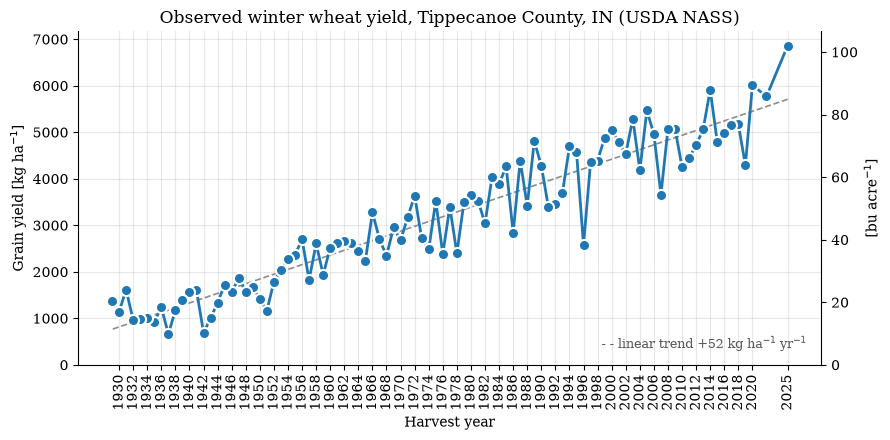

In [12]:
from simpest.models import observed_yield

indiana_yield_data = DATA_DIR / "Tippecanoe_yield_winterwheat_1929-2025.csv"

# visualize the data
# NASS "Year" is the harvest year; read_nass_yield also converts bu/acre to
# kg/ha (winter wheat is 60 lb per bushel, so 1 bu/acre ≈ 67.25 kg/ha).
obs_yield = observed_yield.read_nass_yield(indiana_yield_data)
BU_ACRE_TO_KG_HA = observed_yield.BU_ACRE_TO_KG_HA

years, y_kg = obs_yield["harvest_year"], obs_yield["yield_kg_ha"]
slope, intercept = np.polyfit(years, y_kg, 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(years, intercept + slope * years, color="0.55", lw=1.2, ls="--", zorder=2)
ax.plot(years, y_kg, color="#1f77b4", lw=2, marker="o", ms=8, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
ax.text(0.98, 0.04, f"- - linear trend {slope:+.0f} kg ha$^{{-1}}$ yr$^{{-1}}$", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9, color="0.35")

ax.set_xlabel("Harvest year")
ax.set_ylabel("Grain yield [kg ha$^{-1}$]")
ax.set_title("Observed winter wheat yield, Tippecanoe County, IN (USDA NASS)")
ax.set_xticks(years[::2])
ax.tick_params(axis="x", rotation=90)
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

# Same quantity in the source unit, so a secondary scale is safe here.
sec = ax.secondary_yaxis("right", functions=(lambda v: v / BU_ACRE_TO_KG_HA, lambda v: v * BU_ACRE_TO_KG_HA))
sec.set_ylabel("[bu acre$^{-1}$]")

fig.tight_layout()
plt.show()

### Long-term yield trend

The 1929–2025 record rises steadily as varieties, fertiliser and disease
control improved. A two-segment linear trend (one slope before a breakpoint
year and one after, joined at the breakpoint) is fitted by searching every
breakpoint that leaves at least 10 years on each side. The breakpoint is only
weakly determined: the cell prints the error of the two-segment fit next to
that of a single straight line. Either way, the slope over the simulated
seasons is about the same (~53 kg ha⁻¹ yr⁻¹), and that slope is what the
comparison with the model below relies on.

In [ ]:
# Two-segment (continuous "hinge") linear trend: one slope before a breakpoint
# year and another after it, fitted by a breakpoint grid search that keeps at
# least 10 years on each side (simpest.models.observed_yield).
yield_trend = observed_yield.fit_two_segment_trend(
    obs_yield["harvest_year"], obs_yield["yield_kg_ha"], min_segment_years=10)
bp_year, slope_pre, slope_post = yield_trend.breakpoint, yield_trend.slope_before, yield_trend.slope_after
print(f"Breakpoint {bp_year}: {slope_pre:+.1f} kg ha-1 yr-1 before, {slope_post:+.1f} kg ha-1 yr-1 after")
# The breakpoint is only worth reading into if it clearly beats a single straight line.
print(f"RMSE two-segment {yield_trend.rmse:.0f} kg ha-1 vs single line {yield_trend.rmse_single_line:.0f} kg ha-1")

x_obs = obs_yield["harvest_year"].to_numpy(float)

# Reindex to every year so the line breaks at the years NASS did not report.
all_years = np.arange(int(x_obs.min()), int(x_obs.max()) + 1)
y_full = obs_yield.set_index("harvest_year")["yield_kg_ha"].reindex(all_years)
missing = all_years[y_full.isna().to_numpy()]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(1972.5, 1991.5, color="0.92", zorder=0)
ax.text(1982, 0.97, "simulated seasons\n(harvest 1973–1991)", transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=8, color="0.35")
ax.plot(all_years, y_full, color="#1f77b4", lw=1.6, marker="o", ms=4, zorder=3, label="Observed (NASS)")
ax.plot(all_years, yield_trend(all_years), color="0.2", lw=1.4, ls="--", zorder=4,
        label=f"Two-segment trend: {slope_pre:+.0f} → {slope_post:+.0f} kg ha$^{{-1}}$ yr$^{{-1}}$")
ax.axvline(bp_year, color="0.5", lw=1, ls=":", zorder=2)
ax.annotate(f"breakpoint {bp_year}", xy=(bp_year, yield_trend([bp_year])[0]), xytext=(6, -28),
            textcoords="offset points", fontsize=8, color="0.35")

ax.set_xlabel("Harvest year")
ax.set_ylabel("Grain yield [kg ha$^{-1}$]")
ax.set_title("Observed winter wheat yield, Tippecanoe County, IN (USDA NASS, 1929–2025)")
ax.set_ylim(0, None)
ax.margins(x=0.01)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
sec = ax.secondary_yaxis("right", functions=(lambda v: v / BU_ACRE_TO_KG_HA, lambda v: v * BU_ACRE_TO_KG_HA))
sec.set_ylabel("[bu acre$^{-1}$]")
ax.legend(loc="upper left", frameon=False, fontsize=9)
if len(missing):
    ax.text(0.99, 0.03, "no NASS value: " + ", ".join(map(str, missing)), transform=ax.transAxes,
            ha="right", va="bottom", fontsize=8, color="0.35")

fig.tight_layout()
plt.show()

In [4]:
# crop_params.iopt

## Run the model — potential production (no water or nutrient stress)

The production level is controlled by two switches:

- `crop_params.iopt` — the crop run mode:

| `iopt` | Mode                      |
| ------ | ------------------------- |
| 1      | **Potential (no stress)** |
| 2      | Water-limited             |
| 3      | Water + N limited         |
| 4      | Water + N + P + K limited |

- `soil_params.irri` — the irrigation mode (`0` = rain-fed, `1` = automatic
  refill to field capacity, `2` = scheduled table).

For **potential production** we set `iopt = 1` (nutrients non-limiting) _and_
`irri = 1` (automatic irrigation), so both the nutrient stress index and the
water-stress factor `TRANRF` stay at `1` throughout the growing season.


In [5]:
# Winter-wheat crop parameters in potential mode (IOPT=1): nutrient stress is switched off.
crop_params = CropParameters(crop_name="wheat")
crop_params.iopt = torch.tensor(1.0)

# Runtime override (not a package edit): the "wheat" preset's default TSUM2=1000
# (anthesis->maturity thermal sum) reaches DVS=2 before some seasons' septoria
# reference observations end -- 1980 by 8 days, 1984 by 17 days (see
# probe_tsum2.py). TSUM2=1450 was picked by probing candidate values against
# every season's last reference observation date; it's the smallest value in
# that sweep for which every season's simulated maturity is at or after its
# last reference date (1984 is the tightest, now 5 days past instead of 17
# short). Raising it delays maturity in all six seasons, not just the two that
# were short -- harmless (the extra days just have no reference to compare
# against) but it does shift every season's simulated yield/AGB.
crop_params.tsum1 = torch.tensor(1651.0)
crop_params.tsum2 = torch.tensor(730.0)

# Assemble every location (one per sowing season) into one batch and run a single forward pass.
samples = [dataset[i] for i in range(len(dataset))]
weather, soil_params, site_params = collate_torchcrop(samples)

# Automatic irrigation (IRRI=1): the root zone is refilled to field capacity,
# so soil water never limits growth and TRANRF stays at 1 (potential water supply)
soil_params.irri = torch.tensor(1.0)

# Move every tensor input onto the target device.
crop_params = crop_params.to(device=device)
soil_params = soil_params.to(device=device)
site_params = site_params.to(device=device)
weather = weather.to(device=device)

model = Lintul5Model(crop_params, soil_params, site_params).eval().to(device)
with torch.no_grad():
    output = model(weather, start_doy=1)

# Per-location summary at maturity.
results = pd.DataFrame(
    {
        "location": list(dataset.locations),
        "yield_g_m2": np.round(output.yield_.tolist(), 2),
        "adjusted_yield_g_m2": np.round(output.adjusted_yield.tolist(), 2),
        "max_lai": np.round(output.lai.max(dim=1).values.tolist(), 2),
        "final_dvs": output.dvs[:, -1].tolist(),
    }
)
results

,location,yield_g_m2,adjusted_yield_g_m2,max_lai,final_dvs
0,1972,672.83,668.37,5.92,2.0
1,1973,642.75,642.75,5.31,2.0
2,1974,660.53,654.64,6.48,2.0
3,1975,769.50,769.50,5.61,2.0
4,1976,717.00,712.76,6.66,2.0
5,1977,682.00,665.51,6.80,2.0
6,1978,717.64,714.02,6.13,2.0
7,1979,754.69,752.64,6.26,2.0
8,1980,664.69,664.69,6.05,2.0
9,1981,790.90,790.90,6.87,2.0


### Potential vs observed yield

The model uses one fixed variety and management for every season, so it has
no technology trend. To compare like with like, each observed yield is
**detrended** with the two-segment trend above and expressed at the
technology level of the last simulated harvest year. The observed yields are
also converted to dry matter (NASS reports grain at 13.5 % moisture), and each
season is matched to its NASS harvest year (sowing year + 1).

The left panel compares the levels (the gap between the curves is the yield
gap). The right panel compares year-to-year anomalies: if the weather-driven
potential yield explained the good and bad years, the points would follow the
diagonal.

In [ ]:
# Compare the observed yields of the simulated seasons with torchcrop's
# potential yield. Two adjustments make them comparable:
#   1. Year alignment: a season sown in year y is harvested (and reported by
#      NASS) in y + 1.
#   2. Technology: the model uses one fixed variety and management, so the
#      observed yields are detrended with the two-segment trend and expressed
#      at the technology level of the last simulated harvest year.
# NASS yields are at 13.5 % grain moisture; Lintul5's WSO is dry matter.
G_M2_TO_KG_HA = 10.0

sow_years = np.array([int(y) for y in dataset.locations])
ref_harvest_year = int(sow_years.max()) + 1
cmp_df = observed_yield.compare_with_potential(
    obs_yield, sow_years, results["yield_g_m2"].to_numpy() * G_M2_TO_KG_HA, yield_trend,
    ref_harvest_year=ref_harvest_year,
)

# Year-to-year anomalies (deviation from each series' own mean): does the
# weather-only potential yield explain the good and bad years?
valid = cmp_df.dropna(subset=["observed"])
anom_pot = valid["potential"] - valid["potential"].mean()
anom_obs = valid["observed_detrended"] - valid["observed_detrended"].mean()
r_anom = np.corrcoef(anom_pot, anom_obs)[0, 1]

fig, (ax_ts, ax_sc) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_ts.plot(cmp_df["sow_year"], cmp_df["potential"], color="#ff7f0e", lw=2, marker="s", ms=7,
           markeredgecolor="white", label="Simulated potential (torchcrop)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="#1f77b4", lw=2, marker="o", ms=7,
           markeredgecolor="white", label=f"Observed, detrended to {ref_harvest_year} technology")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed"], color="0.6", lw=1.2, ls="--", marker="o", ms=4,
           label="Observed, as reported")
ax_ts.set_xlabel("Sowing year")
ax_ts.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax_ts.set_title("Potential vs observed yield per season")
ax_ts.set_xticks(cmp_df["sow_year"][::2])
ax_ts.set_ylim(0, None)
ax_ts.legend(loc="lower right", frameon=False, fontsize=9)

lim = 1.1 * max(anom_pot.abs().max(), anom_obs.abs().max())
ax_sc.axhline(0, color="0.6", lw=1)
ax_sc.axvline(0, color="0.6", lw=1)
ax_sc.scatter(anom_pot, anom_obs, s=45, color="#1f77b4", edgecolor="white", linewidth=0.8, zorder=3)
for sy, xa, ya in zip(valid["sow_year"], anom_pot, anom_obs):
    ax_sc.annotate(str(sy), (xa, ya), xytext=(4, 3), textcoords="offset points", fontsize=7, color="0.35")
ax_sc.set_xlim(-lim, lim)
ax_sc.set_ylim(-lim, lim)
ax_sc.set_aspect("equal")
ax_sc.set_xlabel("Potential-yield anomaly [kg ha$^{-1}$]")
ax_sc.set_ylabel("Detrended observed anomaly [kg ha$^{-1}$]")
ax_sc.set_title(f"Year-to-year anomalies (r = {r_anom:.2f}, n = {len(valid)})")

for ax in (ax_ts, ax_sc):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Mean observed/potential ratio (detrended): {cmp_df['yield_gap_ratio'].mean():.2f}")
cmp_df.round(1)

### Calibrate simulated yield (WSO) against detrended observed yield

torchcrop is differentiable, so its parameters can be fitted by gradient
descent. `torchcrop.calibration.CalibrationManager` keeps each parameter
inside its bounds through a sigmoid transform, and L-BFGS minimises the mean
squared error between the simulated storage-organ weight at maturity (WSO)
and the detrended observed yield of every season.

The calibration runs on a **copy** of the model: `model` and `output` above
remain the potential-production run that the rest of the notebook uses.

**What the fit can and cannot do.** One parameter set is shared by all 19
seasons, so the fit moves the level of the simulated yields, not their
season-to-season pattern. The model is still run in potential mode, so the
fitted RUE multiplier is an *effective* value: it absorbs every yield-limiting
factor the model leaves out (water, nitrogen, disease, weeds). It is not a
physiological RUE.

In [ ]:
import copy
from torchcrop.calibration import CalibrationManager, ParameterSpec

# Parameters to fit. The whole batch of seasons shares one parameter set, so
# the fit can move the level of the simulated yield but not its season-to-season
# pattern. A per-season sensitivity check showed that a 10 % change in RUE moves
# every season's yield by almost the same amount (~760 kg ha-1), laicr also acts
# as a near-uniform level shift (so it cannot be told apart from RUE), SLA and
# RGRL have small effects and RDRL has none. Phenology (tsum1/tsum2) is left
# alone because the septoria section below relies on the maturity dates.
CALIB_SPECS = [
    ParameterSpec("crop.scale_factor_rue", bounds=(0.2, 1.5)),
]
MAX_EVALS = 30   # each evaluation is one forward + backward pass over all seasons

# Target: detrended observed yield (dry matter) per season, in kg ha-1.
target_kg_ha = torch.tensor(cmp_df["observed_detrended"].to_numpy(), dtype=torch.float32, device=device)
has_obs = ~torch.isnan(target_kg_ha)

# Calibrate a copy so `model` and `output` above stay the potential-production run.
calib_model = Lintul5Model(copy.deepcopy(crop_params), soil_params, site_params).to(device)
calib_mgr = CalibrationManager(calib_model, CALIB_SPECS)

# L-BFGS with a line search: few parameters and a smooth objective, so it
# converges in a handful of evaluations. The latents are unconstrained; the
# manager maps them into the bounds on every materialize().
optimizer = torch.optim.LBFGS(calib_mgr.parameters(), lr=1.0, max_iter=MAX_EVALS, max_eval=MAX_EVALS,
                              tolerance_change=1e-4, line_search_fn="strong_wolfe")
history = []

def closure():
    optimizer.zero_grad()
    values = calib_mgr.materialize()
    sim_kg_ha = calib_model(weather, start_doy=1).yield_ * G_M2_TO_KG_HA
    loss = torch.mean((sim_kg_ha[has_obs] - target_kg_ha[has_obs]) ** 2)
    loss.backward()
    history.append({"eval": len(history), "rmse_kg_ha": float(loss.detach().sqrt()),
                    **{k: float(v.detach()) for k, v in values.items()}})
    print(f"eval {history[-1]['eval']:2d}  RMSE {history[-1]['rmse_kg_ha']:7.1f} kg ha-1  "
          + "  ".join(f"{k}={v:.3f}" for k, v in history[-1].items() if k.startswith("crop.")))
    return loss

optimizer.step(closure)
history = pd.DataFrame(history)

# Final forward pass with the calibrated values.
with torch.no_grad():
    calib_values = {k: float(v) for k, v in calib_mgr.materialize().items()}
    calib_output = calib_model(weather, start_doy=1)
cmp_df["calibrated"] = calib_output.yield_.cpu().numpy() * G_M2_TO_KG_HA
print("Calibrated:", {k: round(v, 3) for k, v in calib_values.items()})

valid = cmp_df.dropna(subset=["observed_detrended"])
fit_table = pd.DataFrame({
    "potential": observed_yield.fit_stats(valid["potential"], valid["observed_detrended"]),
    "calibrated": observed_yield.fit_stats(valid["calibrated"], valid["observed_detrended"]),
}).T.round(2)
fit_table

In [ ]:
fig, (ax_ts, ax_loss) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_ts.plot(cmp_df["sow_year"], cmp_df["potential"], color="#ff7f0e", lw=1.4, ls="--", marker="s", ms=5,
           label="Simulated potential (uncalibrated)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["calibrated"], color="#2ca02c", lw=2, marker="s", ms=7,
           markeredgecolor="white", label="Simulated, calibrated")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="#1f77b4", lw=2, marker="o", ms=7,
           markeredgecolor="white", label=f"Observed, detrended to {ref_harvest_year} technology")
ax_ts.set_xlabel("Sowing year")
ax_ts.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax_ts.set_title("Yield per season after calibrating " + ", ".join(s.name for s in CALIB_SPECS))
ax_ts.set_xticks(cmp_df["sow_year"][::2])
ax_ts.set_ylim(0, None)
ax_ts.legend(loc="lower right", frameon=False, fontsize=9)

ax_loss.plot(history["eval"], history["rmse_kg_ha"], color="#2ca02c", lw=2)
ax_loss.set_xlabel("Model evaluation")
ax_loss.set_ylabel("RMSE [kg ha$^{-1}$]")
ax_loss.set_title("Calibration loss")
ax_loss.set_ylim(0, None)

for ax in (ax_ts, ax_loss):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

## Visualizing the results

The model returns two per-day trajectories that we visualise the same way:

- **State variables** — `output.states`, a list of `ModelState`
  holding the model's stored pools (biomass, LAI, soil water, nutrient pools, …).
- **Diagnostic variables** — `output.diagnostics`, a list of `DiagnosticState`
  holding the intermediate fluxes and stress factors computed each
  day (TRANRF, RUE, partitioning fractions, transpiration, …).

Each weather series starts on 1 January, but the crop is autumn-sown at that
season's own `IDPL` (varies year to year — see `site.csv`); masking to the
sowing latch makes every curve **start at the day of sowing**. The short
near-vertical segment at DVS `0` is the sowing→emergence interval; DVS then
climbs `0 → 1` (anthesis) `→ 2` (maturity).


In [6]:
from matplotlib.lines import Line2D

# Pick five random (reproducible) locations
rng = np.random.default_rng(42)
selected_idx = rng.choice(len(dataset.locations), size=5, replace=False)
locations = [dataset.locations[i] for i in selected_idx]
n_loc = len(locations)
colors = [
    "#1f77b4",  # blue
    "#d62728",  # red
    "#2ca02c",  # green
    "#ff7f0e",  # orange
    "#9467bd",  # purple
]

def mask_until_dvs2(sown_mask, dvs_vals):
    """Boolean mask selecting sown days up to and including maturity (DVS >= 2).

    Args:
        sown_mask: ``[L]`` bool array, ``True`` once the crop is sown.
        dvs_vals:  ``[L]`` development-stage values.

    Returns:
        ``[L]`` bool mask: sown days with index <= the first day DVS reaches 2.
    """
    mature = np.where(dvs_vals >= 2.0)[0]
    cutoff = mature[0] if len(mature) else len(dvs_vals)
    return sown_mask & (np.arange(len(dvs_vals)) <= cutoff)


def plot_trajectories(traj, dvs, sown, field_names, meta, *, title, ncols=4):
    """Plot every channel of ``traj`` against DVS, one line per location.

    A single helper used for both state and diagnostic figures so they share
    the same style, grid layout, labelling and legend.

    Args:
        traj:        ``[B, L, C]`` stacked trajectory array.
        dvs:         ``[B, L]`` development stage (x-axis).
        sown:        ``[B, L]`` sowing latch (> 0 once sown).
        field_names: length-``C`` list naming the channels of ``traj``.
        meta:        ``{field: (label, unit)}`` used for the panel titles.
        title:       figure super-title.
        ncols:       number of subplot columns.
    """
    nrows = int(np.ceil(len(field_names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 2.4 * nrows), sharex=True)
    axes = axes.ravel()

    for ax, fld in zip(axes, field_names):
        j = field_names.index(fld)
        for c, b in enumerate(selected_idx):
            mask = mask_until_dvs2(sown[b] > 0, dvs[b])
            ax.plot(dvs[b][mask], traj[b, mask, j], color=colors[c], lw=1.2, alpha=0.9)
        label, unit = meta.get(fld, (fld, ""))
        ax.set_title(f"{label} [{unit}]" if unit else label, fontsize=11)
        ax.grid(alpha=0.3)
        ax.margins(x=0.02)

    # Hide unused panels; label the x-axis on the bottom row of plotted panels.
    for ax in axes[len(field_names):]:
        ax.axis("off")
    for ax in axes[max(0, len(field_names) - ncols):len(field_names)]:
        ax.set_xlabel("DVS")

    handles = [Line2D([0], [0], color=colors[i], lw=2) for i in range(n_loc)]
    fig.legend(
        handles,
        [str(loc) for loc in locations],
        title="Location",
        loc="lower center",
        ncol=n_loc,
        fontsize=12,
        bbox_to_anchor=(0.5, 0.01),
        frameon=False,
    )
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=[0, 0.04, 1, 0.99])
    plt.show()

### State variables vs DVS

Stack the per-day `ModelState` snapshots into a `[B, T+1, C]` array and plot
every stored state variable against DVS with the shared helper.


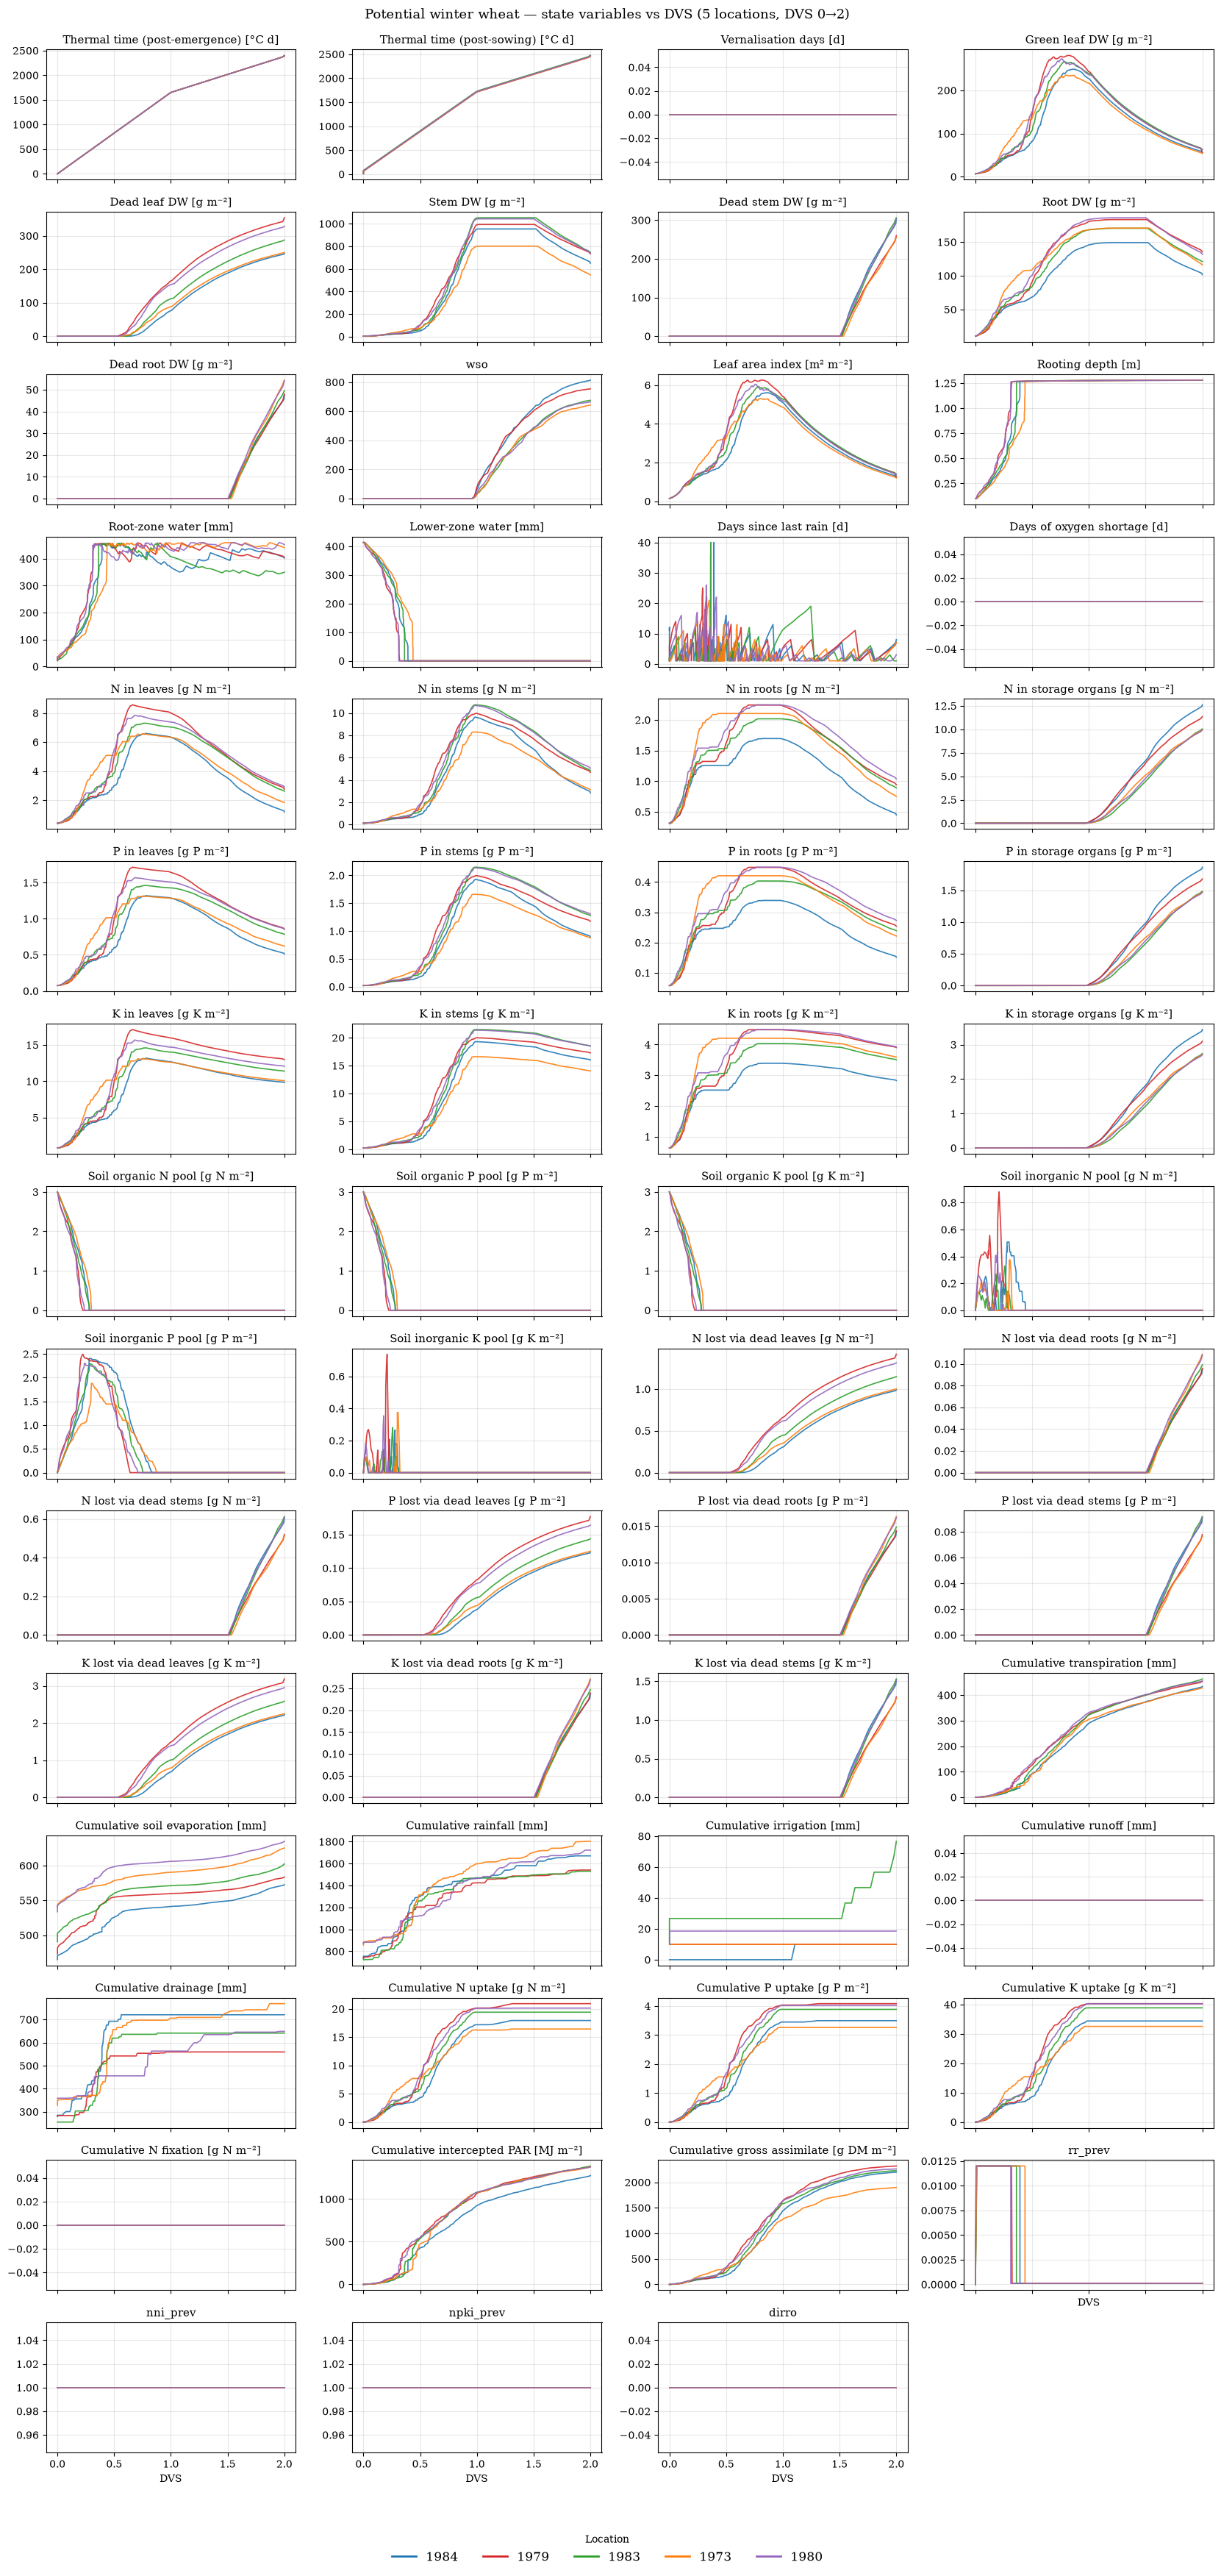

In [7]:
# Label + unit for each ModelState field.
STATE_META = {
    "tsum": ("Thermal time (post-emergence)", "°C d"),
    "tsump": ("Thermal time (post-sowing)", "°C d"),
    "vern": ("Vernalisation days", "d"),
    "wlv": ("Green leaf DW", "g m⁻²"),
    "wlvd": ("Dead leaf DW", "g m⁻²"),
    "wst": ("Stem DW", "g m⁻²"),
    "wstd": ("Dead stem DW", "g m⁻²"),
    "wrt": ("Root DW", "g m⁻²"),
    "wrtd": ("Dead root DW", "g m⁻²"),
    "wso": ("Storage organ DW", "g m⁻²"),
    "lai": ("Leaf area index", "m² m⁻²"),
    "rootd": ("Rooting depth", "m"),
    "wa": ("Root-zone water", "mm"),
    "wa_lower": ("Lower-zone water", "mm"),
    "dslr": ("Days since last rain", "d"),
    "dsos": ("Days of oxygen shortage", "d"),
    "anlv": ("N in leaves", "g N m⁻²"),
    "anst": ("N in stems", "g N m⁻²"),
    "anrt": ("N in roots", "g N m⁻²"),
    "anso": ("N in storage organs", "g N m⁻²"),
    "aplv": ("P in leaves", "g P m⁻²"),
    "apst": ("P in stems", "g P m⁻²"),
    "aprt": ("P in roots", "g P m⁻²"),
    "apso": ("P in storage organs", "g P m⁻²"),
    "aklv": ("K in leaves", "g K m⁻²"),
    "akst": ("K in stems", "g K m⁻²"),
    "akrt": ("K in roots", "g K m⁻²"),
    "akso": ("K in storage organs", "g K m⁻²"),
    "nmin": ("Soil organic N pool", "g N m⁻²"),
    "pmin": ("Soil organic P pool", "g P m⁻²"),
    "kmin": ("Soil organic K pool", "g K m⁻²"),
    "nmint": ("Soil inorganic N pool", "g N m⁻²"),
    "pmint": ("Soil inorganic P pool", "g P m⁻²"),
    "kmint": ("Soil inorganic K pool", "g K m⁻²"),
    "nlossl": ("N lost via dead leaves", "g N m⁻²"),
    "nlossr": ("N lost via dead roots", "g N m⁻²"),
    "nlosss": ("N lost via dead stems", "g N m⁻²"),
    "plossl": ("P lost via dead leaves", "g P m⁻²"),
    "plossr": ("P lost via dead roots", "g P m⁻²"),
    "plosss": ("P lost via dead stems", "g P m⁻²"),
    "klossl": ("K lost via dead leaves", "g K m⁻²"),
    "klossr": ("K lost via dead roots", "g K m⁻²"),
    "klosss": ("K lost via dead stems", "g K m⁻²"),
    "tran_cum": ("Cumulative transpiration", "mm"),
    "evap_cum": ("Cumulative soil evaporation", "mm"),
    "rain_cum": ("Cumulative rainfall", "mm"),
    "irrig_cum": ("Cumulative irrigation", "mm"),
    "runoff_cum": ("Cumulative runoff", "mm"),
    "drain_cum": ("Cumulative drainage", "mm"),
    "nuptr_cum": ("Cumulative N uptake", "g N m⁻²"),
    "puptr_cum": ("Cumulative P uptake", "g P m⁻²"),
    "kuptr_cum": ("Cumulative K uptake", "g K m⁻²"),
    "nfixtr_cum": ("Cumulative N fixation", "g N m⁻²"),
    "parint_cum": ("Cumulative intercepted PAR", "MJ m⁻²"),
    "gtotal_cum": ("Cumulative gross assimilate", "g DM m⁻²"),
}

# Stack the per-day ModelState snapshots into a [B, T+1, C] array.
field_names = output.states[0].field_names
state_traj = torch.stack([s.stack() for s in output.states], dim=1).cpu().numpy()  # [B, T+1, C]
dvs_traj = output.dvs.cpu().numpy()  # [B, T+1]
sown_traj = torch.stack([s.sown for s in output.states], dim=1).cpu().numpy()  # [B, T+1]

# DVS itself and the binary sowing latch are not informative state curves.
plot_fields = [f for f in field_names if f not in ("dvs", "sown")]
plot_idx = [field_names.index(f) for f in plot_fields]

plot_trajectories(
    state_traj[:, :, plot_idx],
    dvs_traj,
    sown_traj,
    plot_fields,
    STATE_META,
    title="Potential winter wheat — state variables vs DVS (5 locations, DVS 0→2)\n",
)

### Diagnostic variables vs DVS

The diagnostics are the intermediate fluxes and stress factors computed each
day — stress factors (`TRANRF`, NNI, …), photosynthesis drivers (`RUE`,
`GTOTAL`), light interception, phenology drivers, water/nutrient fluxes and
partitioning fractions.


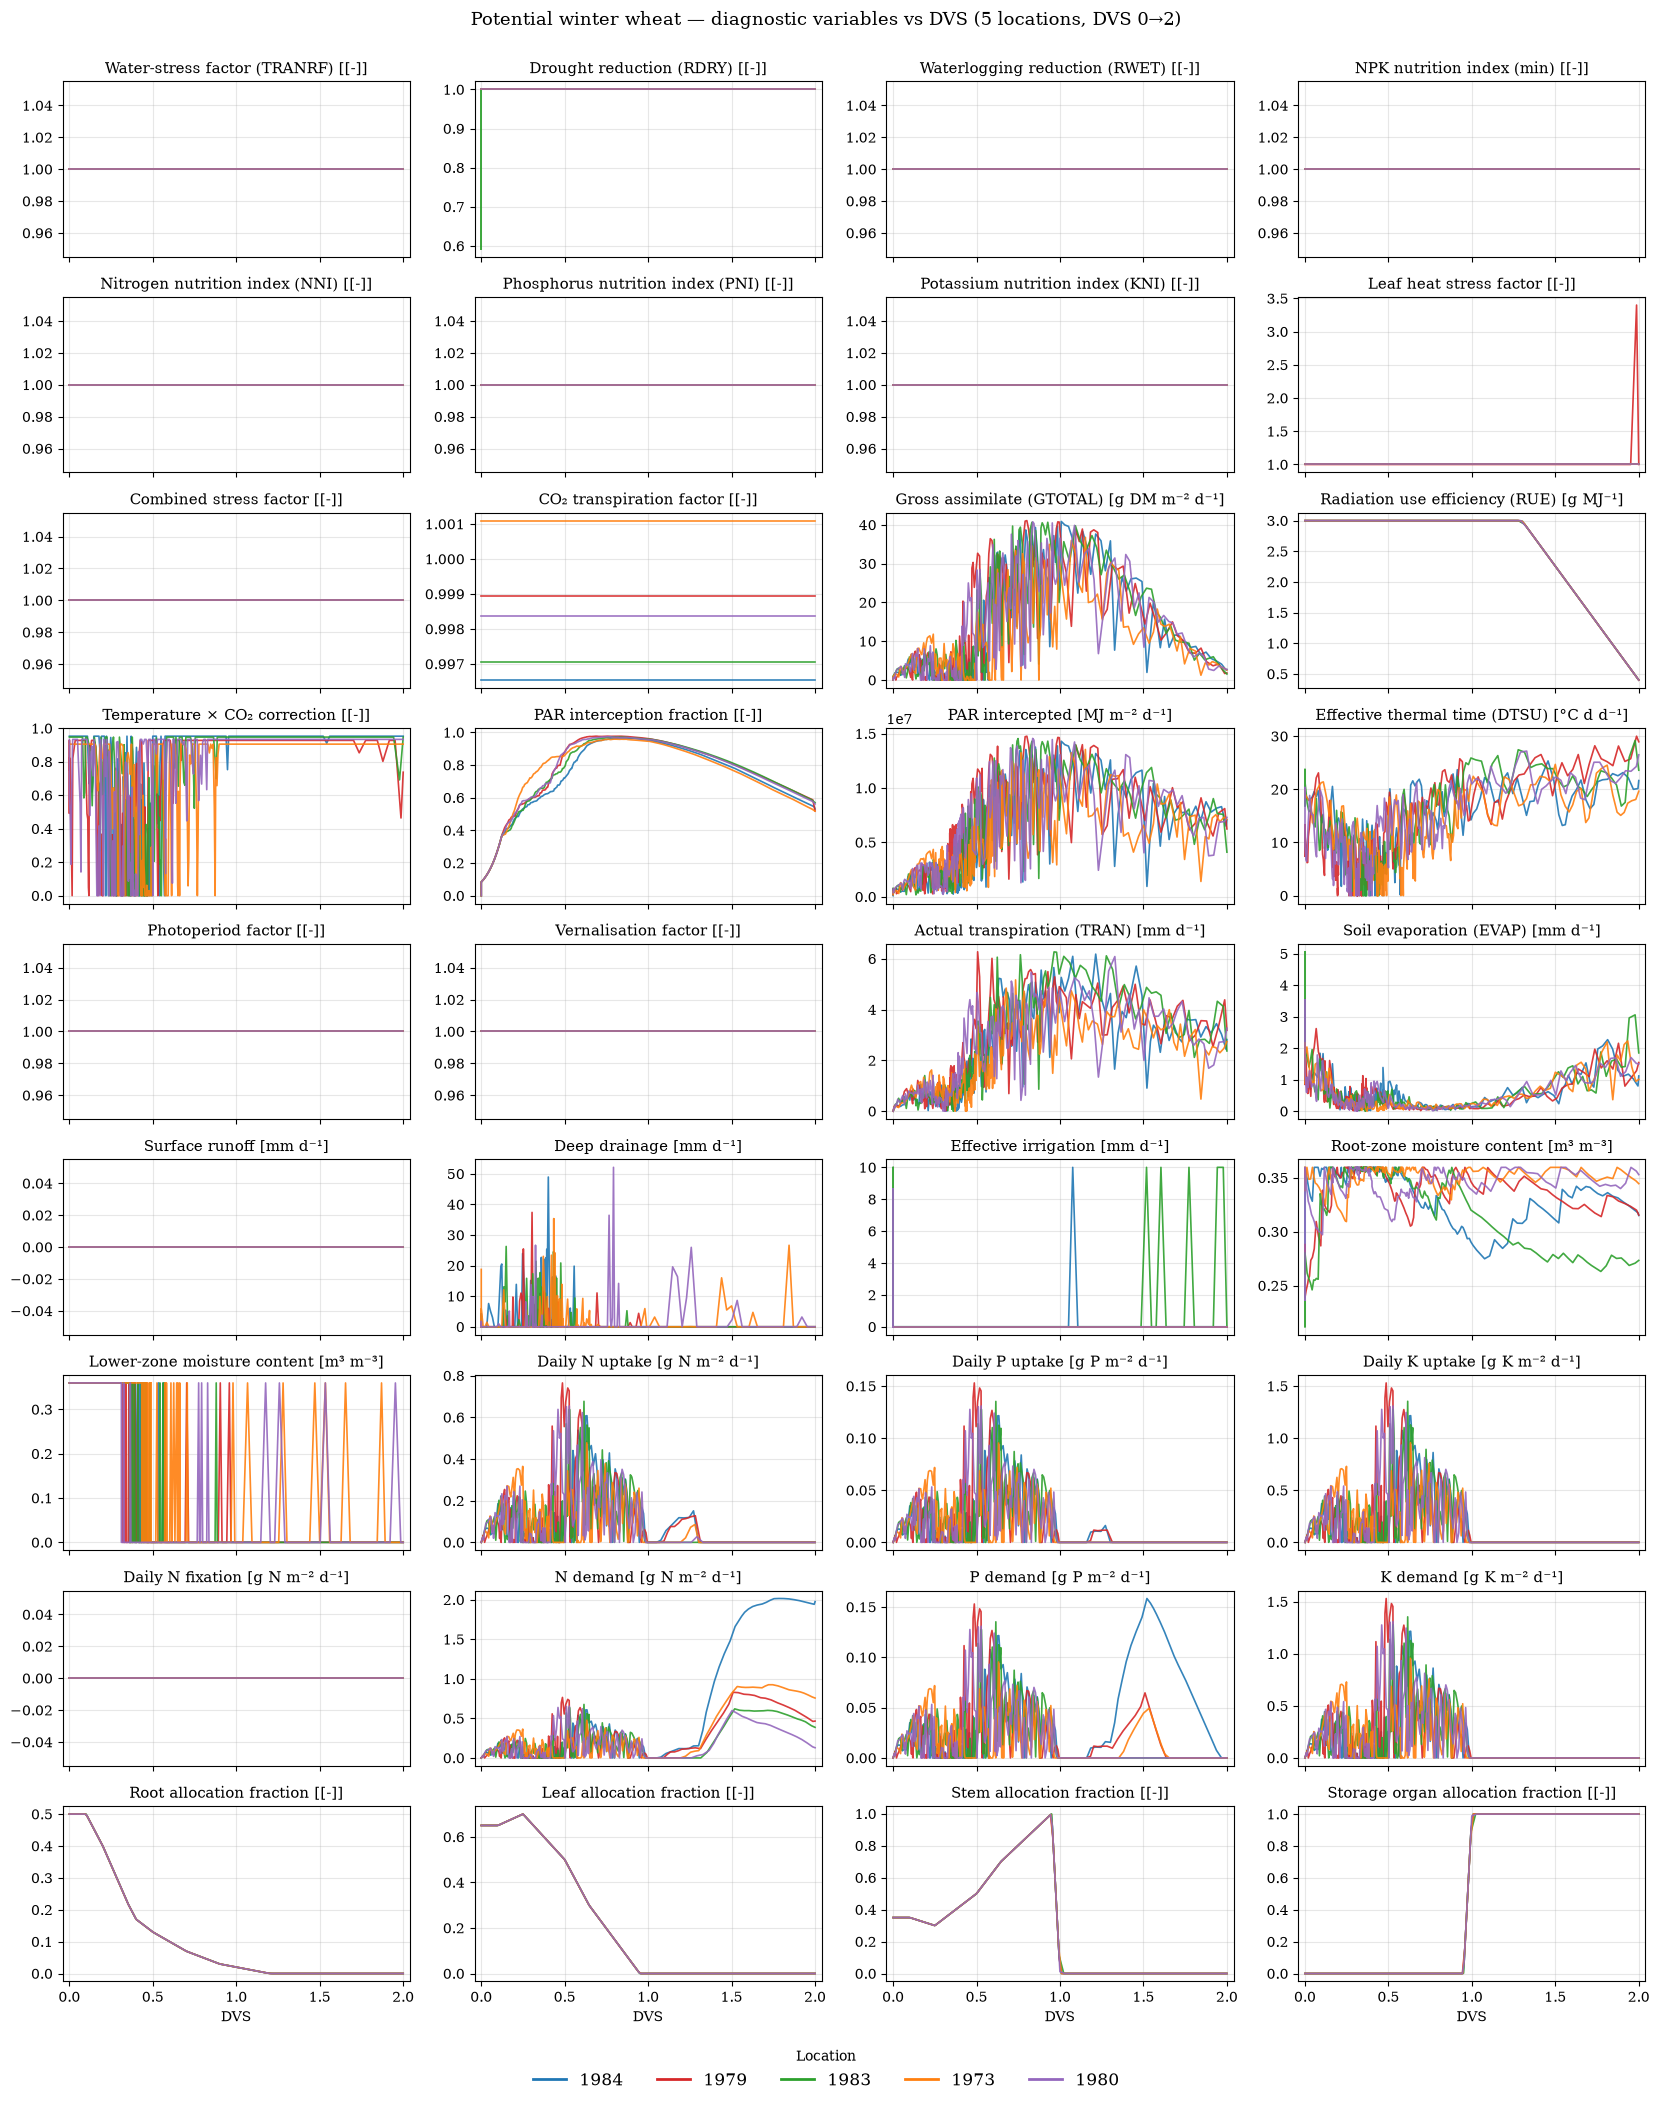

In [8]:
# Label + unit for each DiagnosticState field.
DIAG_META = {
    # Stress factors
    "tranrf": ("Water-stress factor (TRANRF)", "[-]"),
    "rdry": ("Drought reduction (RDRY)", "[-]"),
    "rwet": ("Waterlogging reduction (RWET)", "[-]"),
    "nstress": ("NPK nutrition index (min)", "[-]"),
    "nni": ("Nitrogen nutrition index (NNI)", "[-]"),
    "pni": ("Phosphorus nutrition index (PNI)", "[-]"),
    "kni": ("Potassium nutrition index (KNI)", "[-]"),
    "leaf_heat_factor": ("Leaf heat stress factor", "[-]"),
    "combined_stress": ("Combined stress factor", "[-]"),
    "co2_factor": ("CO₂ transpiration factor", "[-]"),
    # Photosynthesis / growth drivers
    "gtotal": ("Gross assimilate (GTOTAL)", "g DM m⁻² d⁻¹"),
    "rue": ("Radiation use efficiency (RUE)", "g MJ⁻¹"),
    "rtmco": ("Temperature × CO₂ correction", "[-]"),
    # Light / canopy
    "frac_intercepted": ("PAR interception fraction", "[-]"),
    "parint": ("PAR intercepted", "MJ m⁻² d⁻¹"),
    # Phenology drivers
    "dtsu": ("Effective thermal time (DTSU)", "°C d d⁻¹"),
    "photofac": ("Photoperiod factor", "[-]"),
    "vernfac": ("Vernalisation factor", "[-]"),
    # Water fluxes
    "tran": ("Actual transpiration (TRAN)", "mm d⁻¹"),
    "evap": ("Soil evaporation (EVAP)", "mm d⁻¹"),
    "runoff": ("Surface runoff", "mm d⁻¹"),
    "drain": ("Deep drainage", "mm d⁻¹"),
    "rirr": ("Effective irrigation", "mm d⁻¹"),
    "smact": ("Root-zone moisture content", "m³ m⁻³"),
    "smactl": ("Lower-zone moisture content", "m³ m⁻³"),
    # Nutrient fluxes
    "nuptr": ("Daily N uptake", "g N m⁻² d⁻¹"),
    "puptr": ("Daily P uptake", "g P m⁻² d⁻¹"),
    "kuptr": ("Daily K uptake", "g K m⁻² d⁻¹"),
    "nfixtr": ("Daily N fixation", "g N m⁻² d⁻¹"),
    "n_demand": ("N demand", "g N m⁻² d⁻¹"),
    "p_demand": ("P demand", "g P m⁻² d⁻¹"),
    "k_demand": ("K demand", "g K m⁻² d⁻¹"),
    # Partitioning fractions
    "fr": ("Root allocation fraction", "[-]"),
    "fl": ("Leaf allocation fraction", "[-]"),
    "fs": ("Stem allocation fraction", "[-]"),
    "fo": ("Storage organ allocation fraction", "[-]"),
}

# Stack the per-day DiagnosticState snapshots into a [B, T, C] array.
diag_field_names = output.diagnostics[0].field_names
diag_traj = torch.stack([s.stack() for s in output.diagnostics], dim=1).cpu().numpy()  # [B, T, C]

plot_trajectories(
    diag_traj,
    dvs_traj[:, :-1],
    sown_traj[:, :-1],
    diag_field_names,
    DIAG_META,
    title="Potential winter wheat — diagnostic variables vs DVS (5 locations, DVS 0→2)\n",
)

In [ ]:
# Potential yield trajectory of every season, one line per sowing year.
# Sowing year is an ordered variable, so the lines are shaded along a single
# sequential ramp (with a colorbar) instead of 19 categorical colours.
WSO_IDX = field_names.index("wso")
G_M2_TO_KG_HA = 10.0   # torchcrop states are g m-2; agronomic yields are kg ha-1

sow_years = [int(y) for y in dataset.locations]
norm = plt.matplotlib.colors.Normalize(vmin=min(sow_years), vmax=max(sow_years))
cmap = plt.get_cmap("viridis")

fig, ax = plt.subplots(figsize=(9, 5.5))
grain_fill_start = []
for b, sow_year in enumerate(sow_years):
    mask = mask_until_dvs2(sown_traj[b] > 0, dvs_traj[b])
    yield_kg_ha = state_traj[b, mask, WSO_IDX] * G_M2_TO_KG_HA
    grain_fill_start.append(int(np.argmax(yield_kg_ha > 1.0)))
    ax.plot(np.arange(len(yield_kg_ha)), yield_kg_ha,
            color=cmap(norm(sow_year)), lw=1.6, alpha=0.9)

# Nothing happens before grain filling, so start the axis just ahead of it.
ax.set_xlim(max(0, min(grain_fill_start) - 15), None)

ax.set_xlabel("Days after sowing")
ax.set_ylabel("Yield (storage organs) [kg ha$^{-1}$]")
ax.set_title("Potential winter wheat — yield trajectory per season")
ax.grid(alpha=0.3)
ax.margins(x=0.01)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02)
cbar.set_label("Sowing year")
cbar.set_ticks([y for y in sow_years if y % 3 == 0])

fig.tight_layout()
plt.show()


## 6. Feed the torchcrop run into FraNchEstYN (septoria + fungicide)

torchcrop simulates crop growth only — no pest, disease, or fungicide
effects. `simpest.models.franchestyn` layers a septoria SEIR epidemic and a
fungicide-efficacy model on top of an external **attainable** crop-growth
trajectory (light interception, biomass, yield, thermal time), then reports
the **actual** (disease-limited) trajectory. The nineteen seasons already run
above supply that attainable trajectory; the cells below convert torchcrop's
in-memory tensors into the three DataFrames `run_franchestyn` expects
(`weather_df`, `management_df`, `crop_model_df`), matching the column
contracts in `simpest/models/fr_weather_reader.py`,
`fr_reference_reader.py`, and `fr_data.py`.

Reference septoria-severity observations for this same West Lafayette site
are reused from `notebooks/data/reference_fra/FRA_REFERENCE_Indiana.csv`
(1973–1991) to calibrate the disease parameters — this run's torchcrop-driven
crop growth is independent of that file's origin, only the location and
disease-observation years need to line up with our 1972–1991 window.

**Weather for the disease model.** Septoria infection is driven by leaf
wetness and humidity, so the weather fed to FraNchEstYN matters more than it
does for torchcrop. `FRANCH_WEATHER_MODE` picks one of three options:

| mode | what the disease model sees |
|---|---|
| `"daily"` | daily Tmax/Tmin/rain/radiation only. RH is estimated from temperature alone, and a day's rain is spread evenly over 24 h, so any day with ≥ 4.8 mm of rain counts as 24 wet hours |
| `"daily_rh"` | as `"daily"`, plus measured daily RH extremes (RHmax/RHmin) |
| `"hourly"` | measured hourly temperature, RH, rain and radiation (ERA5, from `tools/fetch_torchcrop_dataset.py --hourly`) |

In the daily path, April–June contains 352 fully-wet days across the 19
seasons, an artifact of spreading each day's rain over 24 h; the hourly path
has 6. With hourly weather the humidity parameters also become influential in
the Morris screen. On fit alone the two modes are tied once calibration is
done properly (see *Calibration* below): mean objective RMSE over three seeds
was 14.8 for `"daily"` and 15.0 for `"hourly"`. `"daily"` is the default here. `"hourly"` is the more physically faithful
input and gives more realistic season-to-season variation in peak severity,
so switch to it when that matters more than the objective RMSE.


In [9]:
import simpest.models.franchestyn as franchestyn

FRANCH_CROP_TYPE      = "wheat"
FRANCH_DISEASE_TYPE   = "septoria"
FRANCH_FUNGICIDE_TYPE = "protectant"   # no sprays scheduled below -> runs as a no-op
FRANCH_SITE           = "west_lafayette_indiana"
FRANCH_VARIETY        = "Generic"
FRANCH_DISEASE        = "thisDisease"
FRANCH_START_YEAR     = 1972
FRANCH_END_YEAR       = 1991   # last season's (1990 sowing) disease dynamics run into mid-1991
FRANCH_USE_GDD        = True   # required whenever the crop-model series comes from an
                                # internal (Python) crop model rather than calendar-day
                                # interpolation -- see UNITS_INVESTIGATION notes.
# Weather fed to the disease model -- see the table above.
FRANCH_WEATHER_MODE   = "daily_rh"   # "daily", "daily_rh" or "hourly"
FRANCH_LATITUDE       = 40.4698
REFERENCE_PATH = Path("../data/reference_fra/FRA_REFERENCE_Indiana.csv")

In [10]:
from simpest.models import fr_inputs

ref_df = pd.read_csv(REFERENCE_PATH)
# Weather: concatenate the 6 season CSVs and drop duplicate dates (the season
# windows overlap by design -- see build_seasons.py); overlapping days carry
# identical values since every season file was sliced from the same source.
weather_raw = pd.concat(
    [
        pd.read_csv(dataset.weather_dir / f"{loc}.csv", parse_dates=["Date"], dayfirst=True)
        for loc in dataset.locations
    ], ignore_index=True,
    ).drop_duplicates(subset="Date").sort_values("Date").reset_index(drop=True)

# Hourly ERA5 records for the same period (tools/fetch_torchcrop_dataset.py
# --hourly). torchcrop only needs the daily files above; these give the disease
# model measured humidity and rain timing.
weather_hourly = pd.read_csv(DATA_DIR / "weather_hourly" / "west_lafayette.csv.gz")

weather_df = fr_inputs.build_weather_df(weather_raw, site=FRANCH_SITE, mode=FRANCH_WEATHER_MODE,
                                        weather_hourly=weather_hourly)

# Management: site.csv already has one row per sowing year (IDPL = sowingDOY).
management_df = fr_inputs.build_management_df(dataset.site_data, site=FRANCH_SITE, crop=FRANCH_CROP_TYPE,
                                              variety=FRANCH_VARIETY)

print(f"weather_df ({FRANCH_WEATHER_MODE}): {len(weather_df)} rows, "
      f"{weather_raw['Date'].min().date()} .. {weather_raw['Date'].max().date()}")

weather_df (daily_rh): 7145 rows, 1972-01-01 .. 1991-07-24


In [11]:
# Pull a named field out of the stacked trajectories -> [B, T] numpy, end-of-day aligned.
def sf(field):
    return state_traj[:, 1:, field_names.index(field)]

def df_(field):
    return diag_traj[:, :, diag_field_names.index(field)]

# torchcrop -> FraNchEstYN unit bridge. torchcrop's biomass states are g m-2 (torchcrop/states/model_state.py);
# FraNchEstYN's CropModelData.agb/.yield_ contract is kg ha-1 (simpest/models/fr_data.py). 1 g/m2 = 10 kg/ha.
G_M2_TO_KG_HA = 10.0

# Each season runs from its sowing day to the first day DVS reaches 2 (maturity);
# build_crop_model_df concatenates the seasons into one multi-year series.
crop_model_df = fr_inputs.build_crop_model_df(
    agb=(sf("wlv") + sf("wlvd") + sf("wst") + sf("wstd") + sf("wso")) * G_M2_TO_KG_HA,
    yield_=sf("wso") * G_M2_TO_KG_HA,
    fint=df_("frac_intercepted"),
    gdd=sf("tsum"),   # thermal time since emergence, torchcrop's analogue of SIMPLACE TSUM
    dvs=dvs_traj[:, 1:],
    sow_years=[int(y) for y in dataset.locations],
    sowing_doys=dataset.site_data.loc[dataset.locations, "IDPL"].astype(int).tolist(),
)
print(crop_model_df.tail())

      year  doy           agb        yield      fint          gdd  season
5266  1991  167  18556.619141  6386.369629  0.629229  2310.849609    1990
5267  1991  168  18609.728516  6439.478516  0.614218  2331.949707    1990
5268  1991  169  18665.621094  6495.370117  0.599948  2355.399658    1990
5269  1991  170  18711.335938  6541.086426  0.584534  2379.149658    1990
5270  1991  171  18745.861328  6575.609863  0.569047  2403.499756    1990


In [12]:
fr_cfg = franchestyn.FranchestynConfig(
    crop_type=FRANCH_CROP_TYPE,
    disease_type=FRANCH_DISEASE_TYPE,
    fungicide_type=FRANCH_FUNGICIDE_TYPE,
    site=FRANCH_SITE,
    variety=FRANCH_VARIETY,
    disease=FRANCH_DISEASE,
    is_calibration=True,
    calibration_variable="disease",
    use_gdd=FRANCH_USE_GDD,
    use_prev_day_alignment=True,
    weather_time_step="hourly" if FRANCH_WEATHER_MODE == "hourly" else "daily",
    latitude=FRANCH_LATITUDE,
)

# Single, consistent choice for the whole notebook: every calibration stage below
# reads fr_cfg.optimizer/n_jobs, so set them once here rather than per-stage --
# switching optimizer mid-notebook would leave later stages silently using
# whatever a previous stage last set (and Nelder-Mead-only knobs like n_restarts
# would then be ignored).
fr_cfg.optimizer = "optuna"  # "nelder-mead" or "optuna"; used by every stage below

# Fan independent model evaluations (Nelder-Mead restarts / Morris trajectory
# points / Optuna trials) out across worker processes instead of running them
# one at a time -- respected by whichever optimizer is chosen above.
fr_cfg.n_jobs = 5

# Damage-coefficient params excluded from calibration (cannot be identified from severity data alone).
damage_disable = {"RUEreducerDamage", "LightStealerDamage", "SenescenceAcceleratorDamage", "AssimilateSappersDamage",}
fr_cfg.disease_parameters = franchestyn.deactivate_calibration(fr_cfg.disease_parameters, damage_disable)

# Bound override (notebook only -- fr_disease_parameters.json keeps the canonical
# FraNchEstYN bounds). Calibrations with the canonical max of 0.3 kept pushing
# PathogenSpread (daily secondary-infection rate) to that edge, and the observed
# epidemics rise faster than the simulated ones. Doubling the max improved the
# hourly-weather fit by ~1 RMSE on average over three seeds; with daily weather
# it made no measurable difference (14.8 either way). Set to {} for the
# canonical bounds.
BOUND_OVERRIDES = {"PathogenSpread": {"max": 0.6}}

franchestyn.apply_bound_overrides(fr_cfg.disease_parameters, BOUND_OVERRIDES)

# Mechanistic groups, in dependency order (see notebook discussion): C (cardinal
# temperatures) feeds both B's hourly infection-efficiency calc and A's
# latency/sporulation GDD progress; B's accumulated hydrothermal-time state
# feeds A's onset gate; D (inoculum/spread magnitude) is a pure scale on top
# of A+B+C, so it's calibrated last.
GROUPS = [
    ("A: onset & cycle timing", {"HydroThermalTimeOnset", "CyclePercentageOnset", "LatencyDuration", "SporulationDuration",}),
    ("B: environmental infection-trigger", {"WetnessDurationOptimum", "WetnessDurationMinimum", "DryCriticalInterruption","RelativeHumidityCritical", "RelativeHumidityNotLimiting", "Rain50Detachment",}),
    ("C: temperature response", {"Tmin", "Topt", "Tmax"}),
    ("D: inoculum & spread magnitude", {"OuterInoculumMax", "OuterInoculumShapeParameter", "PathogenSpread",}),
]


In [13]:
from simpest.models import fr_diagnostics
from simpest.models.fr_session import FranchestynSession

# One session holds the inputs and builds the FranchestynRunner once, so the
# weather is parsed a single time for every screen, calibration and forward
# run below. Every run applies fr_cfg's current parameter specs.
session = FranchestynSession(
    fr_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_df,
)
seasons = list(dataset.locations)

## Parameter sensitivity screen (Morris)

`run_morris_sensitivity` uses the *same* parameter selection as calibration
(flagged for `calibration`, `disease` scope, damage parameters excluded) and the
same RMSE objective. Cost is about `n_trajectories * (k + 1)` model runs.

- **mu_star** - mean absolute effect on the severity RMSE. Higher = more
  influential.
- **sigma** - spread of the effects. High relative to mu_star = non-linear or
  interacting with other parameters.
- **mu_star_conf** - bootstrap confidence interval on mu_star.


In [14]:
from simpest.models import fr_sensitivity

# Screen every non-damage disease parameter. Re-enable them all first, in case a staged calibration above left only one group active or edited their values.
sa_params = set().union(*(names for _, names in GROUPS))
franchestyn.deactivate_calibration(fr_cfg.disease_parameters, set(fr_cfg.disease_parameters) - sa_params - damage_disable,)
for p in sa_params:
    fr_cfg.disease_parameters[p]["calibration"] = True

fr_cfg.is_calibration = True  # screen the calibration objective, as calibration runs it

sa = fr_sensitivity.run_morris_sensitivity(
    start_year=FRANCH_START_YEAR, end_year=FRANCH_END_YEAR, config=fr_cfg,
    weather_df=weather_df, management_df=management_df,
    crop_model_df=crop_model_df, ref_df=ref_df,
    n_trajectories=20, seed=50,
    runner=session.runner,
)
sa_df = sa["table"]
sa_df


- Morris screening 16 parameters: 20 trajectories -> 340 model runs.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_OuterInoculumShapeParameter']
- Evaluating 340 trajectory points across up to 5 worker processes (per-run progress is not shown while parallel; per-run completion is reported below).


[Parallel(n_jobs=5)]: Using backend LokyBackend with 5 concurrent workers.
[Parallel(n_jobs=5)]: Done   3 tasks      | elapsed:    4.7s
[Parallel(n_jobs=5)]: Done   8 tasks      | elapsed:    6.9s
[Parallel(n_jobs=5)]: Done  15 tasks      | elapsed:   11.2s
[Parallel(n_jobs=5)]: Done  22 tasks      | elapsed:   15.4s
[Parallel(n_jobs=5)]: Done  31 tasks      | elapsed:   21.0s
[Parallel(n_jobs=5)]: Done  40 tasks      | elapsed:   26.3s
[Parallel(n_jobs=5)]: Done  51 tasks      | elapsed:   33.0s
[Parallel(n_jobs=5)]: Done  62 tasks      | elapsed:   39.5s
[Parallel(n_jobs=5)]: Done  75 tasks      | elapsed:   47.3s
[Parallel(n_jobs=5)]: Done  88 tasks      | elapsed:   55.2s
[Parallel(n_jobs=5)]: Done 103 tasks      | elapsed:  1.1min
[Parallel(n_jobs=5)]: Done 118 tasks      | elapsed:  1.2min
[Parallel(n_jobs=5)]: Done 135 tasks      | elapsed:  1.4min
[Parallel(n_jobs=5)]: Done 152 tasks      | elapsed:  1.6min
[Parallel(n_jobs=5)]: Done 171 tasks      | elapsed:  1.8min
[Parallel(

                          parameter        mu   mu_star     sigma  mu_star_conf
                       disease_Topt -5.379150 16.825950 19.948927      4.718261
           disease_OuterInoculumMax -1.593375 16.635225 20.292389      4.596587
     disease_WetnessDurationOptimum -5.289825 15.896175 18.670356      3.997706
      disease_HydroThermalTimeOnset  7.509750 11.521800 15.659995      5.694878
            disease_LatencyDuration -3.086625 10.793325 13.815636      3.998881
     disease_WetnessDurationMinimum -1.133550  9.578850 12.374536      3.099933
       disease_CyclePercentageOnset -5.997375  6.986925  9.025574      3.439522
                       disease_Tmin  1.271475  4.990425  6.270745      1.572354
disease_RelativeHumidityNotLimiting -2.205825  4.394625  4.896666      1.342595
   disease_RelativeHumidityCritical -1.700475  3.946575  5.076845      1.383015
                       disease_Tmax  1.636200  3.508350  4.180643      1.061993
disease_OuterInoculumShapeParameter -0.0

[Parallel(n_jobs=5)]: Done 340 out of 340 | elapsed:  3.4min finished


,parameter,mu,mu_star,sigma,mu_star_conf
0,disease_Topt,-5.379150,16.825950,19.948927,4.718261
1,disease_OuterInoculumMax,-1.593375,16.635225,20.292389,4.596587
2,disease_WetnessDurationOptimum,-5.289825,15.896175,18.670356,3.997706
3,disease_HydroThermalTimeOnset,7.509750,11.521800,15.659995,5.694878
4,disease_LatencyDuration,-3.086625,10.793325,13.815636,3.998881
5,disease_WetnessDurationMinimum,-1.133550,9.578850,12.374536,3.099933
6,disease_CyclePercentageOnset,-5.997375,6.986925,9.025574,3.439522
7,disease_Tmin,1.271475,4.990425,6.270745,1.572354
8,disease_RelativeHumidityNotLimiting,-2.205825,4.394625,4.896666,1.342595
9,disease_RelativeHumidityCritical,-1.700475,3.946575,5.076845,1.383015


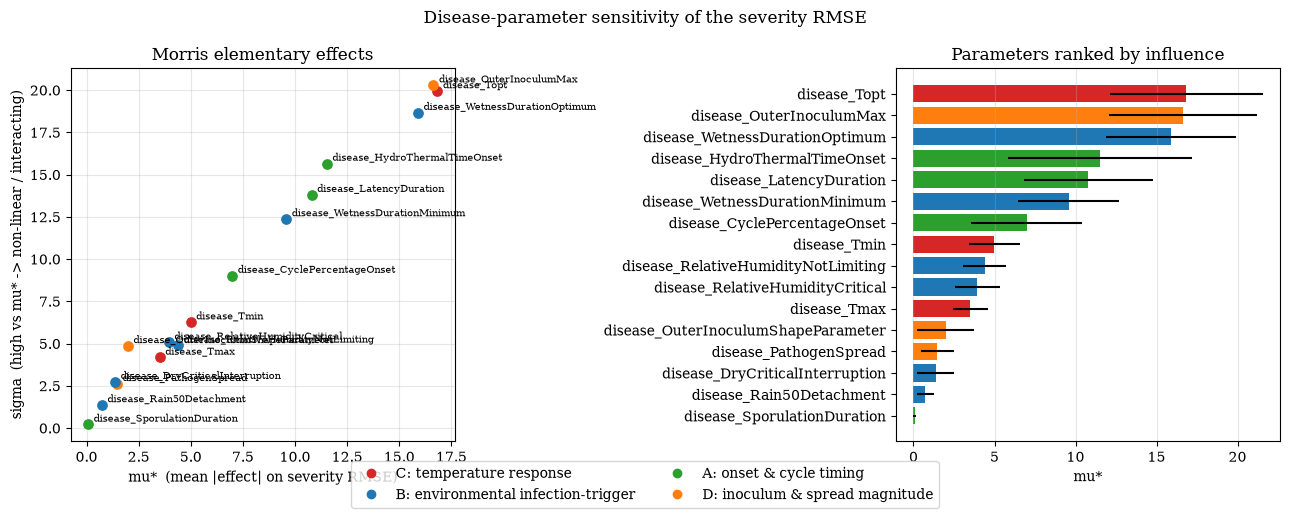

In [15]:
group_of = {p: g for g, names in GROUPS for p in names}
gname = lambda p: group_of.get(p.split('_', 1)[1], '')
gcolors = {
    "C: temperature response": "tab:red",
    "B: environmental infection-trigger": "tab:blue",
    "A: onset & cycle timing": "tab:green",
    "D: inoculum & spread magnitude": "tab:orange",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for _, r in sa_df.iterrows():
    c = gcolors.get(gname(r["parameter"]), "0.5")
    axes[0].scatter(r["mu_star"], r["sigma"], color=c, s=45, zorder=3)
    axes[0].annotate(r["parameter"], (r["mu_star"], r["sigma"]), fontsize=7,
                     xytext=(4, 2), textcoords="offset points")
axes[0].set_xlabel("mu*  (mean |effect| on severity RMSE)")
axes[0].set_ylabel("sigma  (high vs mu* -> non-linear / interacting)")
axes[0].set_title("Morris elementary effects")
axes[0].grid(alpha=0.3)

order = sa_df.sort_values("mu_star")
bar_c = [gcolors.get(gname(p), "0.5") for p in order["parameter"]]
axes[1].barh(order["parameter"], order["mu_star"], color=bar_c,
             xerr=order["mu_star_conf"])
axes[1].set_xlabel("mu*")
axes[1].set_title("Parameters ranked by influence")
axes[1].grid(alpha=0.3, axis="x")

handles = [plt.Line2D([0], [0], marker="o", ls="", color=c, label=g)
           for g, c in gcolors.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Disease-parameter sensitivity of the severity RMSE", fontsize=12)
fig.tight_layout()
plt.show()


In [16]:
# Keep the parameters whose effect is distinguishable from zero; freeze the rest
# at their current values and calibrate only the survivors.
influential = sa_df.loc[sa_df["mu_star"] > 2 * sa_df["mu_star_conf"], "parameter"].tolist()
inert = [p for p in sa_df["parameter"] if p not in influential]
print("influential :", influential)
print("frozen      :", inert)

# sa_df names are runner keys ("disease_<Param>"); fr_cfg.disease_parameters is keyed by "<Param>".
bare = lambda p: p.split("_", 1)[1]
franchestyn.deactivate_calibration(fr_cfg.disease_parameters, {bare(p) for p in inert})
for p in influential:
    fr_cfg.disease_parameters[bare(p)]["calibration"] = True

fr_cfg.is_calibration = True
fr_cfg.n_trials = 300
fr_cfg.seed = 50
reduced = session.run()
print("\nreduced-parameter RMSE:", reduced["outputs"]["summary"]["rmse"])


influential : ['disease_Topt', 'disease_OuterInoculumMax', 'disease_WetnessDurationOptimum', 'disease_HydroThermalTimeOnset', 'disease_LatencyDuration', 'disease_WetnessDurationMinimum', 'disease_CyclePercentageOnset', 'disease_Tmin', 'disease_RelativeHumidityNotLimiting', 'disease_RelativeHumidityCritical', 'disease_Tmax']
frozen      : ['disease_OuterInoculumShapeParameter', 'disease_PathogenSpread', 'disease_DryCriticalInterruption', 'disease_Rain50Detachment', 'disease_SporulationDuration']
- Calibrating 11 using Optuna (TPE), n_trials=300.
- Parameters:
['disease_OuterInoculumMax', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 160/300 CURR RMSE=18.3610 BEST RMSE=16.7350

Trial 300/300 CURR RMSE=17.0000 BEST RMSE=16.2770
Best RMSE: 16.2770
{'disease_OuterInoculumMax': 0.0733130719842704, 'disease_WetnessDurationOptimum': 11.823922665539056, 'disease_WetnessDurationMinimum': 11.162655000353706, 'disease_Tmin': 5.687022689163277, 'disease_Topt': 18.95268919147966, 'disease_Tmax': 29.962390706186216, 'disease_RelativeHumidityCritical': 51.06748309808344, 'disease_RelativeHumidityNotLimiting': 83.50339331554922, 'disease_HydroThermalTimeOnset': 9.59327293886917, 'disease_CyclePercentageOnset': 29.175308500353164, 'disease_LatencyDuration': 24.064743206006597}

reduced-parameter RMSE: 16.277


## Calibration

Earlier versions of this notebook calibrated in staged sweeps (one parameter
group at a time, then a 300-trial joint polish). Comparing procedures with
reproducible seeds showed that a single long joint search does better at
similar cost (objective RMSE, seed 1 for staged, mean of 3 seeds for joint):

| procedure | daily | hourly |
|---|---|---|
| staged sweeps + 300-trial polish | 16.6 | 17.8 |
| joint search, 1200 trials | 14.8 | 16.1 |
| joint search, 1200 trials, `PathogenSpread` max 0.6 | 14.8 | 15.0 |

Results still differ between seeds (about ±0.2 RMSE for daily, ±1 for
hourly), and very different parameter sets reach similar RMSE. The data do not
pin the parameters down well, so the cell below runs several seeds and keeps
the best. It takes roughly 12–15 minutes per seed with `n_jobs=5`.


In [17]:
# Joint calibration of every non-damage parameter, starting from the JSON
# defaults, repeated for several seeds; the best seed wins and its values are
# written into fr_cfg. With fr_cfg.n_jobs > 1 Optuna evaluates trials in fixed
# batches, so each seed is reproducible.
CALIB_SEEDS = [1, 2, 3]
CALIB_TRIALS = 1200

active_names = set().union(*(names for _, names in GROUPS))
for p in active_names:
    fr_cfg.disease_parameters[p]["calibration"] = True

calib = session.calibrate_seeds(CALIB_SEEDS, n_trials=CALIB_TRIALS)
best_run, start_params = calib.best, calib.start_params["disease"]
calib.table().round(3)

- Calibrating 16 using Optuna (TPE), n_trials=1200.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_OuterInoculumShapeParameter']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 1200/1200 CURR RMSE=15.9430 BEST RMSE=15.5950
Best RMSE: 15.5950
{'disease_OuterInoculumMax': 0.12134304067459642, 'disease_PathogenSpread': 0.0322635471533742, 'disease_WetnessDurationOptimum': 21.600495557446504, 'disease_WetnessDurationMinimum': 12.895098964006623, 'disease_DryCriticalInterruption': 26.30627988366594, 'disease_Tmin': 6.2907564369829165, 'disease_Topt': 21.272033415031466,

,1,2,3
RMSE,15.595,15.304,15.490
OuterInoculumMax,0.121,0.190,0.188
PathogenSpread,0.032,0.570,0.297
WetnessDurationOptimum,21.600,36.159,45.690
WetnessDurationMinimum,12.895,11.951,5.498
DryCriticalInterruption,26.306,37.210,17.017
Tmin,6.291,6.651,5.089
Topt,21.272,22.439,22.490
Tmax,31.698,31.478,30.997
RelativeHumidityCritical,51.601,56.479,56.031


In [18]:
# Forward run with the best seed's parameters.
result = session.run_forward()
summary = result["outputs"]["summary"]

# FraNchEstYN stores disease severity as a 0-1 fraction internally;
# build_season_summary expects that and multiplies by 100 for AUDPC, so
# convert to percent only after the summary is built.
simulation_df = fr_diagnostics.simulation_frame(result, severity_percent=False)
season_summary = franchestyn.build_season_summary(simulation_df, site=fr_cfg.site, variety=fr_cfg.variety)
simulation_df["DiseaseSeverity"] = simulation_df["DiseaseSeverity"] * 100.0
season_summary["DiseaseSeverity"] = season_summary["DiseaseSeverity"] * 100.0

print(f"FraNchEstYN completed (best seed: {best_run['seed']})")
print("RMSE (disease severity vs reference):", summary.get("rmse"))
print(f"{len(season_summary)} growing seasons summarised")
season_summary

FraNchEstYN completed (best seed: 2)
RMSE (disease severity vs reference): 15.304
19 growing seasons summarised


,GrowingSeason,Site,Variety,AUDPC,DiseaseSeverity,YieldAttainable,YieldActual,YieldLossRaw,YieldLossPerc,AGBattainable,AGBactual,AveTx,AveTn,AveRHx,AveRHn,TotalPrec,TotalRad,TotalLW
0,1972,west_lafayette_indiana,Generic,3387.143443,88.351628,6728.2560,495.240287,6233.015713,92.639396,19810.402,11267.978635,11.975801,3.588256,88.092527,57.128114,847.3,3597.13,2006.0
1,1973,west_lafayette_indiana,Generic,2717.832373,77.600676,6427.4560,1308.361547,5119.094453,79.644177,17485.826,11781.112252,12.126277,2.951460,87.594891,57.251825,952.4,3439.03,2103.0
2,1974,west_lafayette_indiana,Generic,2500.619270,72.866798,6605.2550,1532.711743,5072.543257,76.795570,20984.360,13619.361771,12.233099,3.498239,88.123239,54.848592,716.9,3901.56,1878.0
3,1975,west_lafayette_indiana,Generic,2222.596432,65.624676,7695.0303,2549.779042,5145.251258,66.864600,20106.598,13859.482841,13.009701,2.696642,85.294776,51.055970,615.8,3780.02,1480.0
4,1976,west_lafayette_indiana,Generic,3131.963599,69.475114,7170.0350,933.677610,6236.357390,86.978061,22415.070,12233.037155,11.254480,1.521864,81.681004,48.838710,597.1,4080.36,1143.0
5,1977,west_lafayette_indiana,Generic,3362.777823,85.654383,6820.0040,433.454958,6386.549042,93.644359,22862.738,12908.516710,10.321555,1.153710,87.250883,58.996466,697.0,4056.95,1607.0
6,1978,west_lafayette_indiana,Generic,3006.293941,74.446937,7176.3600,1011.589814,6164.770186,85.903859,22117.918,13208.864903,11.111150,1.734146,86.790941,55.898955,758.4,3922.55,1792.0
7,1979,west_lafayette_indiana,Generic,2696.787863,82.738616,7546.9270,1081.038909,6465.888091,85.675774,21570.285,14073.960020,11.895789,2.770877,85.754386,53.985965,802.8,3818.79,1646.0
8,1980,west_lafayette_indiana,Generic,2818.896922,84.053992,6646.8660,984.784420,5662.081580,85.184229,20984.736,13604.635826,11.968085,2.698582,84.556738,51.904255,851.4,3838.65,1517.0
9,1981,west_lafayette_indiana,Generic,2738.591746,80.412847,7909.0337,1760.247608,6148.786092,77.743835,22556.846,15363.000731,11.170486,1.536111,87.475694,56.270833,861.9,4043.24,1881.0


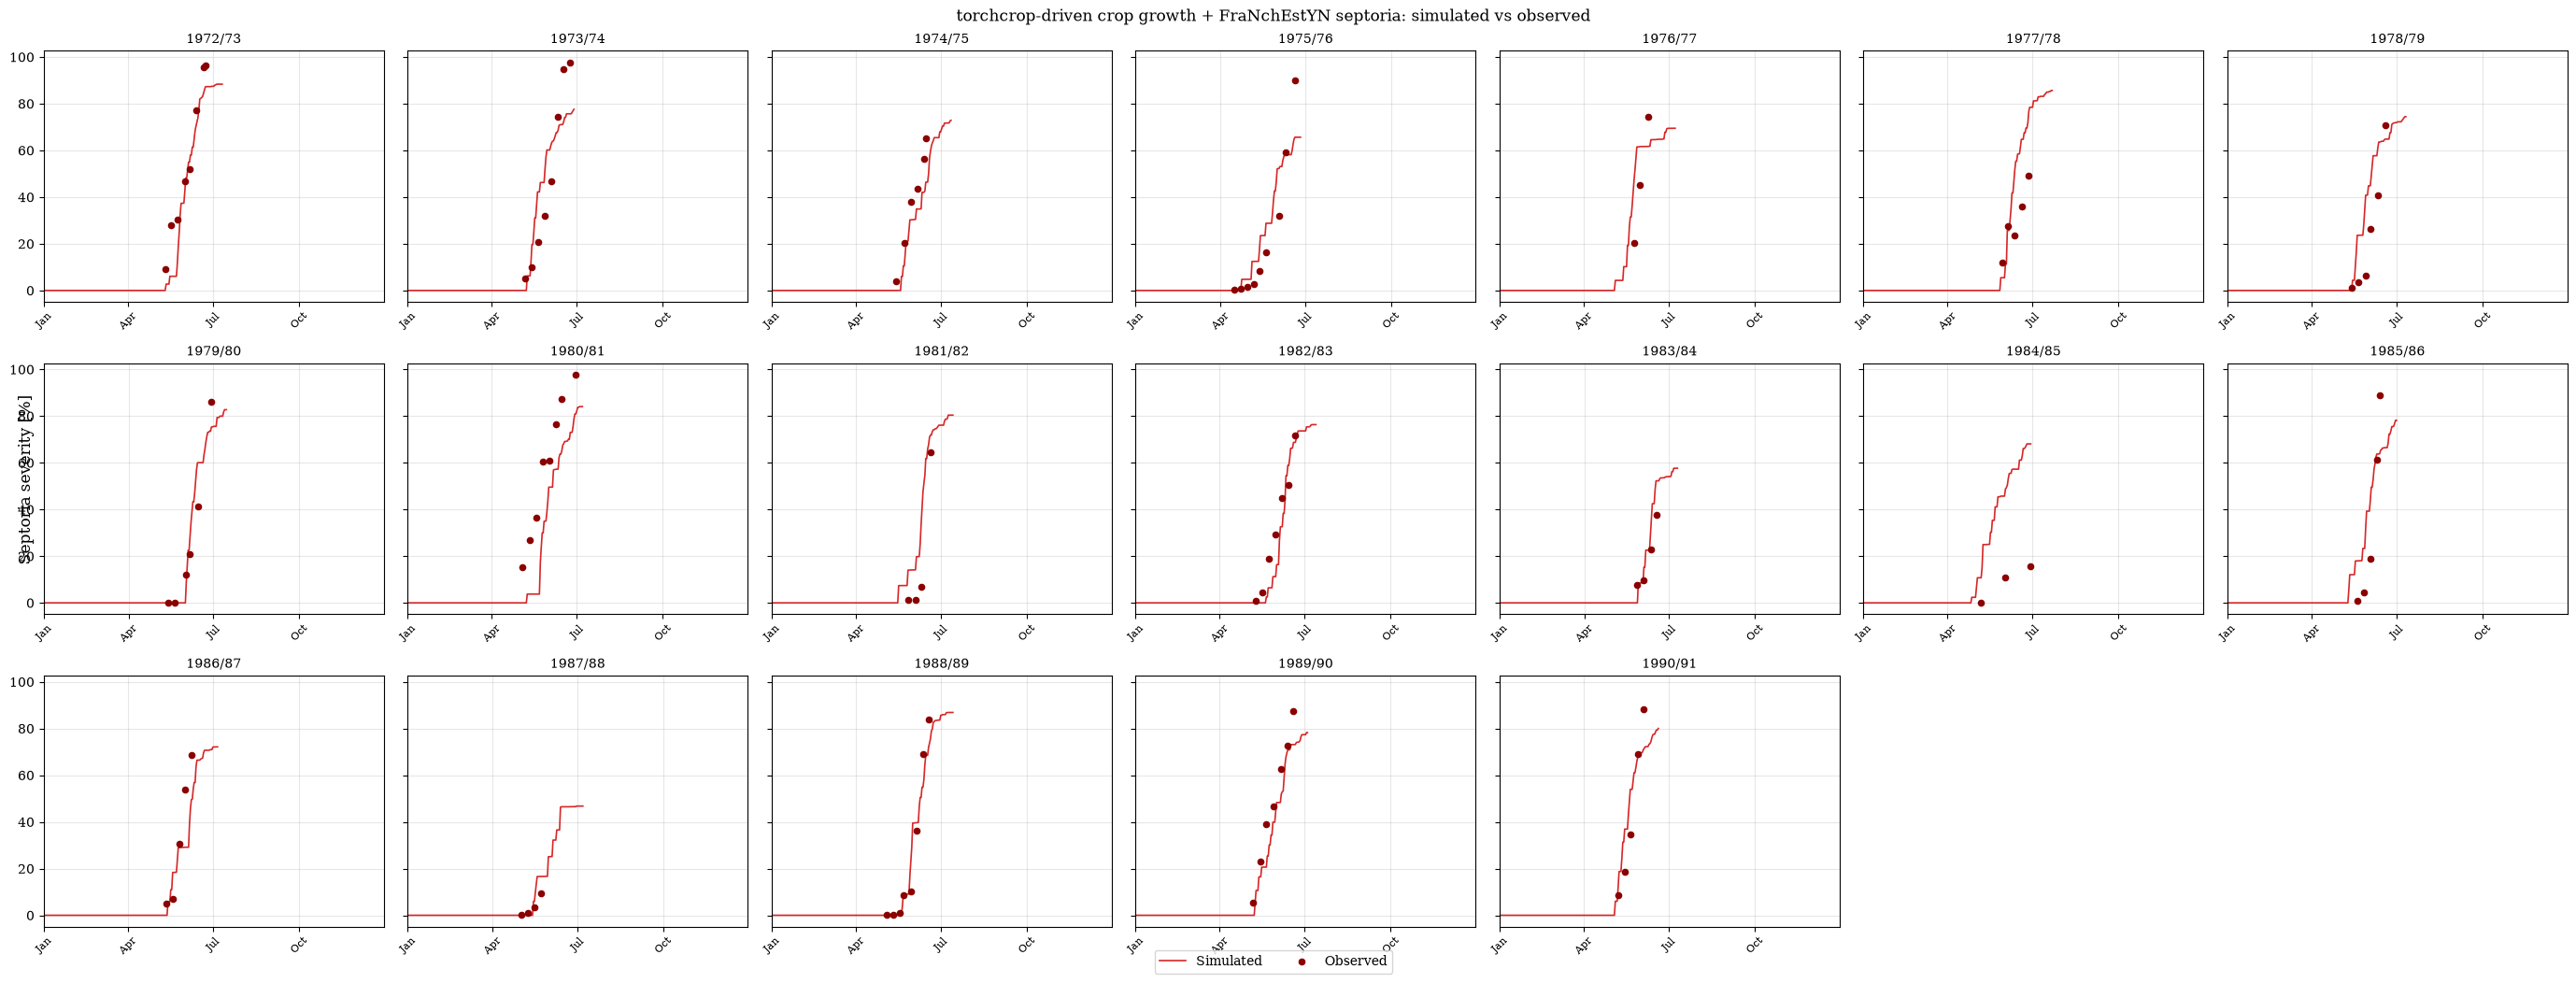

In [19]:
n_seasons = len(dataset.locations)
n_cols = 7
n_rows = int(np.ceil(n_seasons / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 3.5 * n_rows), sharey=True)
axes_flat = axes.ravel()
ref_dis = ref_df[ref_df[FRANCH_DISEASE].notna()]

for i, sow_year in enumerate(dataset.locations):
    ax = axes_flat[i]
    harvest_yr = sow_year + 1
    sub = simulation_df[simulation_df["GrowingSeason"] == sow_year]
    ax.plot(sub["Date"], sub["DiseaseSeverity"], color="tab:red", lw=1.2, label="Simulated")

    ref_yr = ref_dis[ref_dis["year"] == harvest_yr]
    if not ref_yr.empty:
        ref_dates = pd.Timestamp(year=harvest_yr, month=1, day=1) + pd.to_timedelta(ref_yr["DOY"] - 1, unit="D")
        ax.scatter(ref_dates, ref_yr[FRANCH_DISEASE], color="darkred", s=20, zorder=5, label="Observed")

    ax.set_title(f"{sow_year}/{str(harvest_yr)[2:]}", fontsize=10)
    ax.set_xlim(pd.Timestamp(f"{harvest_yr}-01-01"), pd.Timestamp(f"{harvest_yr}-12-31"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.grid(alpha=0.3)

# Hide any unused panels (n_seasons may not fill the grid exactly).
for ax in axes_flat[n_seasons:]:
    ax.axis("off")

handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("Septoria severity [%]")
fig.suptitle("torchcrop-driven crop growth + FraNchEstYN septoria: simulated vs observed", fontsize=12)
fig.tight_layout()
plt.show()

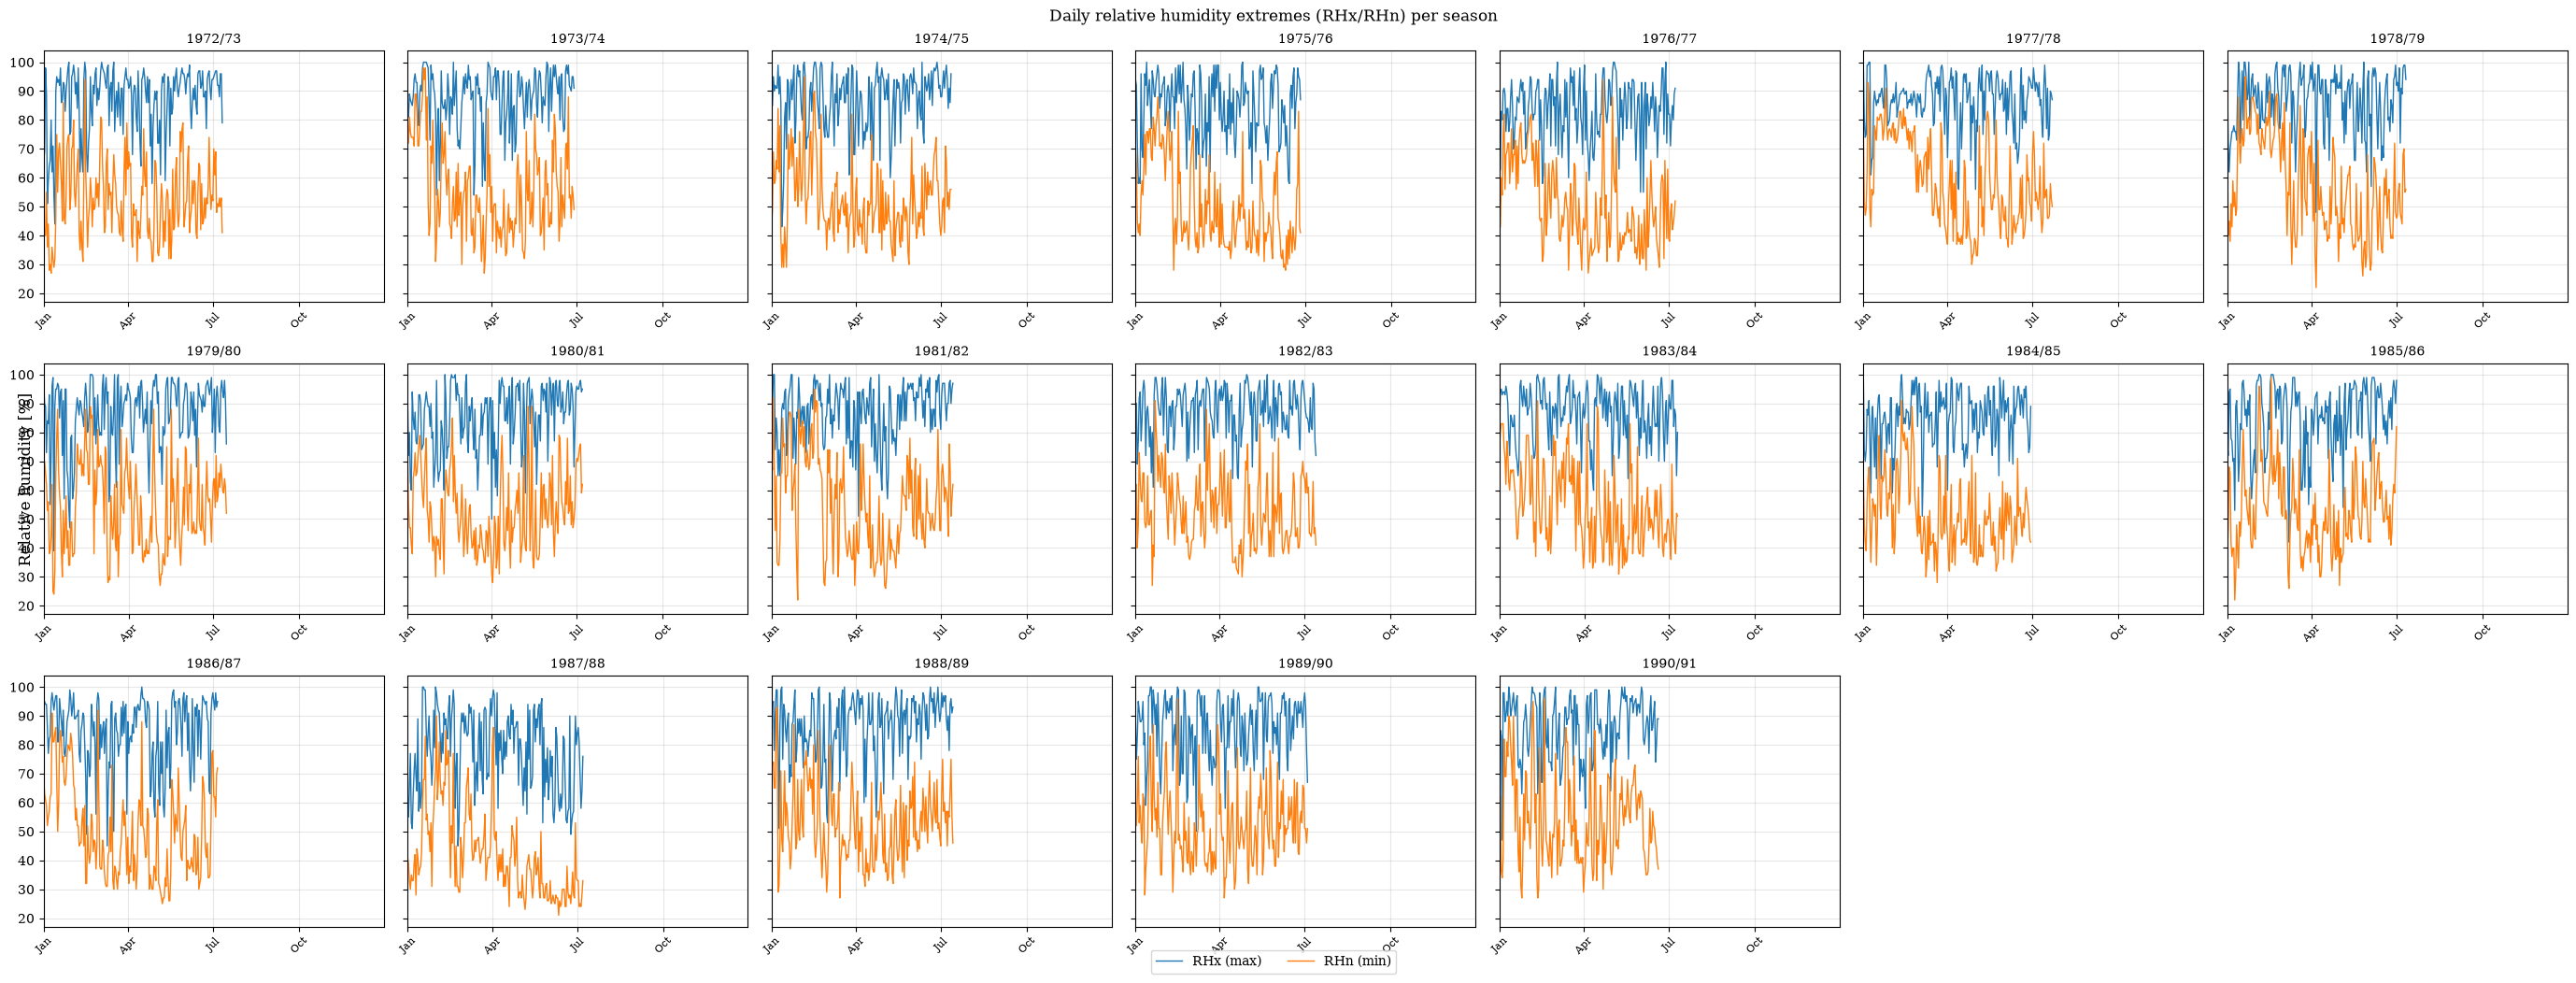

In [20]:
n_seasons = len(dataset.locations)
n_cols = 7
n_rows = int(np.ceil(n_seasons / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 3.5 * n_rows), sharey=True)
axes_flat = axes.ravel()

for i, sow_year in enumerate(dataset.locations):
    ax = axes_flat[i]
    harvest_yr = sow_year + 1
    sub = simulation_df[simulation_df["GrowingSeason"] == sow_year]
    ax.plot(sub["Date"], sub["RHx"], color="tab:blue", lw=1.0, label="RHx (max)")
    ax.plot(sub["Date"], sub["RHn"], color="tab:orange", lw=1.0, label="RHn (min)")

    ax.set_title(f"{sow_year}/{str(harvest_yr)[2:]}", fontsize=10)
    ax.set_xlim(pd.Timestamp(f"{harvest_yr}-01-01"), pd.Timestamp(f"{harvest_yr}-12-31"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.grid(alpha=0.3)

# Hide any unused panels (n_seasons may not fill the grid exactly).
for ax in axes_flat[n_seasons:]:
    ax.axis("off")

handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("Relative humidity [%]")
fig.suptitle("Daily relative humidity extremes (RHx/RHn) per season", fontsize=12)
fig.tight_layout()
plt.show()
plt.close()

## 7. Error diagnostics: simulated vs observed

At every reference observation date (severity from `thisDisease`, canopy
closure from `FINT`), match the simulated value on that same calendar date
and take the residual `simulated - observed`. A parity plot shows overall
bias/spread against the 1:1 line; the residual-over-time plot shows whether
errors cluster in a particular part of the season (color marks over- vs
under-prediction).


In [21]:
severity_err = fr_diagnostics.match_ref_to_sim(simulation_df, ref_df, seasons, FRANCH_DISEASE, "DiseaseSeverity")
fint_err = fr_diagnostics.match_ref_to_sim(simulation_df, ref_df, seasons, "FINT", "LightInterception")

sev_stats, fint_stats = fr_diagnostics.error_stats(severity_err), fr_diagnostics.error_stats(fint_err)
print(f"severity: n={sev_stats['n']}  RMSE={sev_stats['RMSE']:.2f}  MAE={sev_stats['MAE']:.2f}")
print(f"fint:     n={fint_stats['n']}  RMSE={fint_stats['RMSE']:.3f}  MAE={fint_stats['MAE']:.3f}")

severity: n=111  RMSE=15.92  MAE=12.62
fint:     n=31  RMSE=0.243  MAE=0.166


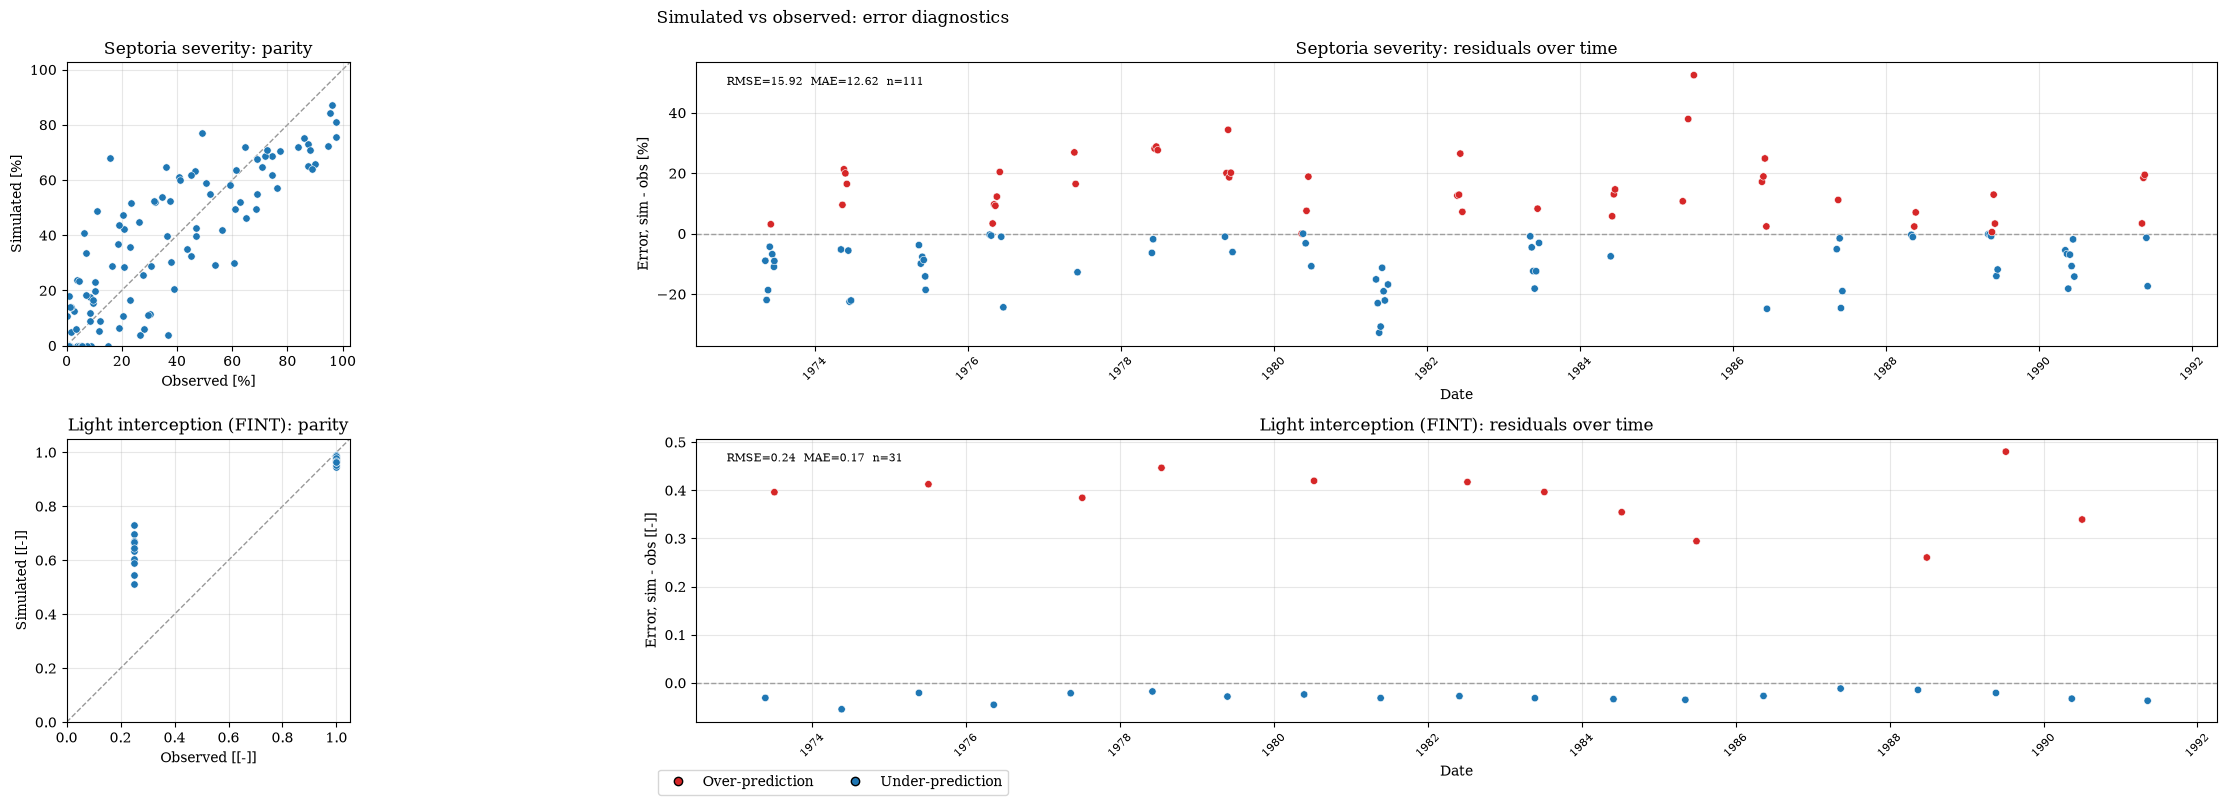

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(28, 8))

panels = [(severity_err, "Septoria severity", "%"), (fint_err, "Light interception (FINT)", "[-]")]
for row, (err_df, label, unit) in enumerate(panels):
    ax_parity, ax_resid = axes[row]

    lo, hi = 0, max(err_df["observed"].max(), err_df["simulated"].max()) * 1.05
    ax_parity.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls="--", zorder=1)
    ax_parity.scatter(err_df["observed"], err_df["simulated"], s=28, color="tab:blue", edgecolor="white", linewidth=0.4, zorder=2)
    ax_parity.set_xlim(lo, hi)
    ax_parity.set_ylim(lo, hi)
    ax_parity.set_aspect("equal")
    ax_parity.set_xlabel(f"Observed [{unit}]")
    ax_parity.set_ylabel(f"Simulated [{unit}]")
    ax_parity.set_title(f"{label}: parity")
    ax_parity.grid(alpha=0.3)

    err_colors = np.where(err_df["error"] >= 0, "tab:red", "tab:blue")
    ax_resid.axhline(0, color="0.6", lw=1, ls="--", zorder=1)
    ax_resid.scatter(err_df["date"], err_df["error"], s=28, color=err_colors, edgecolor="white", linewidth=0.4, zorder=2)
    ax_resid.set_xlabel("Date")
    ax_resid.set_ylabel(f"Error, sim - obs [{unit}]")
    ax_resid.set_title(f"{label}: residuals over time")
    ax_resid.tick_params(axis="x", rotation=45, labelsize=8)
    ax_resid.grid(alpha=0.3)

    rmse = np.sqrt((err_df["error"] ** 2).mean())
    mae = err_df["error"].abs().mean()
    ax_resid.text(0.02, 0.95, f"RMSE={rmse:.2f}  MAE={mae:.2f}  n={len(err_df)}",
                  transform=ax_resid.transAxes, fontsize=8, va="top")

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="tab:red", markersize=6, label="Over-prediction"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="tab:blue", markersize=6, label="Under-prediction"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Simulated vs observed: error diagnostics", fontsize=12)
fig.tight_layout()
plt.show()

### Per-season diagnostics

One row per season: fit quality (same-date RMSE and bias), simulated and
observed peak severity, when the simulated season ends compared with the last
observation, and April–June wet hours. The calibration objective only scores
observations that fall inside a simulated season, so `n_obs_after_season`
counts observations the optimizer never sees. Fully-wet days (24 wet hours)
are mostly an artifact of daily weather, where rain is spread evenly over the
day.


In [23]:
ref_sev = ref_df[ref_df[FRANCH_DISEASE].notna()].copy()
ref_sev["Date"] = fr_diagnostics.reference_dates(ref_sev)

season_diag = fr_diagnostics.season_diagnostics(simulation_df, ref_df, severity_err, seasons, FRANCH_DISEASE)
season_diag.round(1)

,rmse,bias,peak_sim,peak_obs,sim_end,last_obs,n_obs,n_obs_after_season,wet_hours_AMJ,fully_wet_days_AMJ
season,,,,,,,,,,
1972/73,12.2,-9.7,88.4,96.3,1973-07-11,1973-06-23,8,0,629.0,20
1973/74,16.8,1.5,77.6,97.8,1974-06-28,1974-06-24,8,0,868.0,32
1974/75,11.5,-10.5,72.9,65.0,1975-07-12,1975-06-15,6,0,537.0,16
1975/76,12.3,3.2,65.6,90.0,1976-06-26,1976-06-20,9,0,410.0,14
1976/77,19.6,10.2,69.5,74.4,1977-07-08,1977-06-09,3,0,438.0,15
1977/78,22.1,15.3,85.7,49.2,1978-07-22,1978-06-27,5,0,548.0,17
1978/79,19.9,14.4,74.4,70.9,1979-07-11,1979-06-19,6,0,558.0,17
1979/80,9.5,2.1,82.7,86.1,1980-07-15,1980-06-29,6,0,638.0,20
1980/81,22.5,-21.4,84.1,97.8,1981-07-07,1981-06-30,8,0,795.0,29


### Weather drivers per season

Simulated and observed severity together with the drivers of infection:
daily rain (blue bars) and daily wet hours (grey bars) on the right axis.
Sudden steps in the simulated curve that line up with wet spells show where
weather-driven infection events set the epidemic's timing.


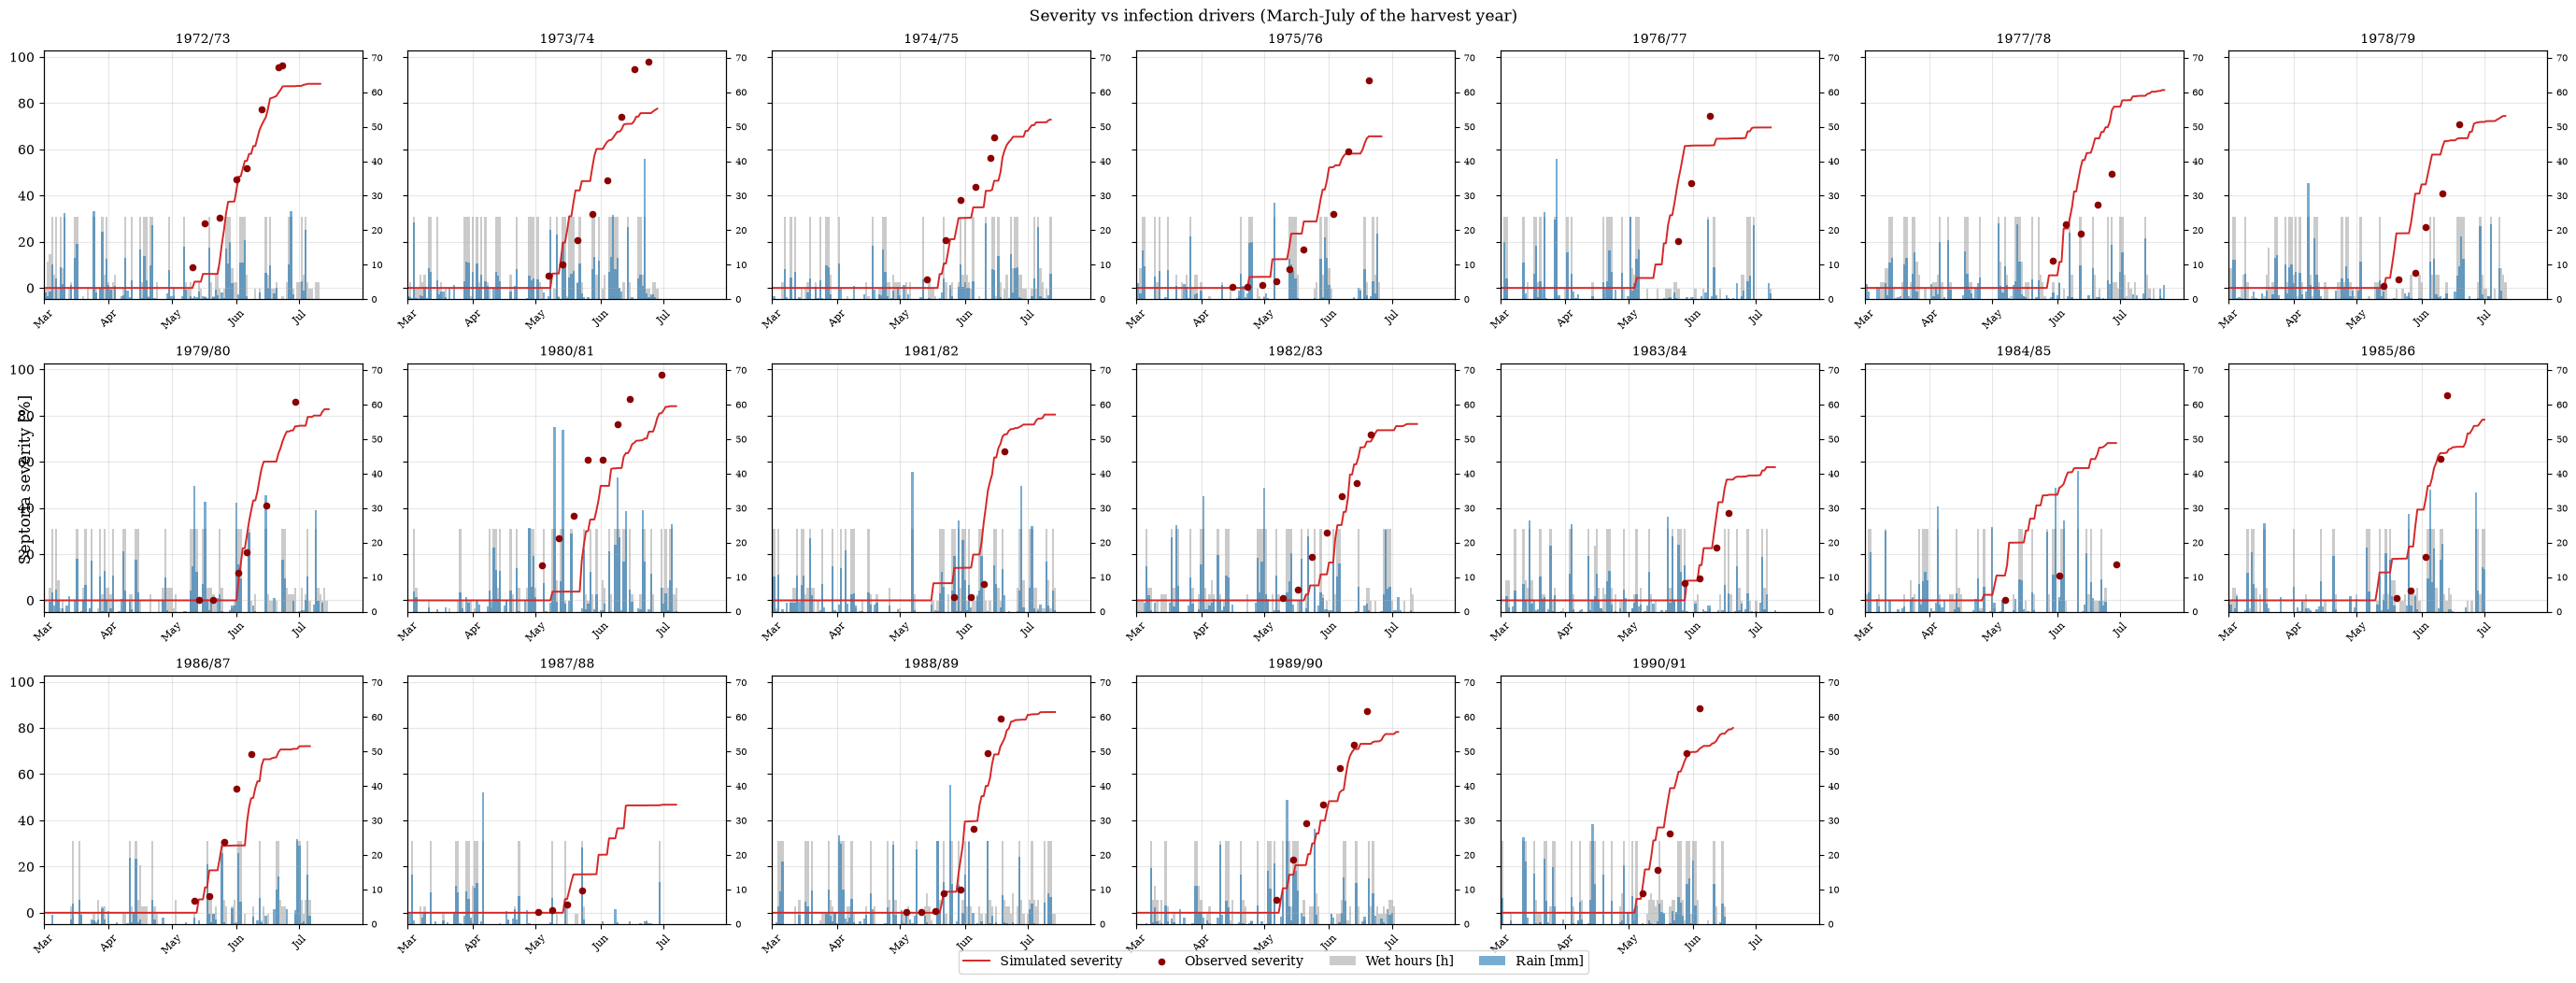

In [24]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 3.5 * n_rows), sharey=True)
axes_flat = axes.ravel()

for i, sow_year in enumerate(dataset.locations):
    ax = axes_flat[i]
    harvest_yr = sow_year + 1
    window = (pd.Timestamp(f"{harvest_yr}-03-01"), pd.Timestamp(f"{harvest_yr}-07-31"))
    sub = simulation_df[(simulation_df["GrowingSeason"] == sow_year) & simulation_df["Date"].between(*window)]

    ax2 = ax.twinx()
    ax2.bar(sub["Date"], sub["TotalLW"], width=1.0, color="0.6", alpha=0.5, label="Wet hours [h]")
    ax2.bar(sub["Date"], sub["TotalPrec"], width=1.0, color="tab:blue", alpha=0.6, label="Rain [mm]")
    ax2.set_ylim(0, 72)  # keep the bars in the lower third, under the severity curve
    ax2.tick_params(axis="y", labelsize=7)

    ax.plot(sub["Date"], sub["DiseaseSeverity"], color="tab:red", lw=1.4, label="Simulated severity")
    obs = ref_sev[ref_sev["year"] == harvest_yr]
    ax.scatter(obs["Date"], obs[FRANCH_DISEASE], color="darkred", s=20, zorder=5, label="Observed severity")
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)

    ax.set_title(f"{sow_year}/{str(harvest_yr)[2:]}", fontsize=10)
    ax.set_xlim(*window)
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.grid(alpha=0.3)

for ax in axes_flat[n_seasons:]:
    ax.axis("off")

h1, l1 = axes_flat[0].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("Septoria severity [%]")
fig.suptitle("Severity vs infection drivers (March-July of the harvest year)", fontsize=12)
fig.tight_layout()
plt.show()


### Why some seasons fit badly

Two patterns account for most of the misfit, and neither goes away with better
weather input, more trials or a wider parameter bound.

1. **Little disease in a wet season (1984/85).** Observed severity peaks at
   16 % although April–mid-June had about 300 mm of rain, above the median of
   these seasons. Its humid hours (RH > 90 %) were few and the spring was warm,
   but the model still produces a sizeable epidemic. A driver the model does
   not see, such as low inoculum, a more resistant cultivar, or how the
   field was scored, is the likely cause. That season also has only 3
   observations, and the last one falls after the simulated season ends.
2. **Simulated epidemics that start too early (1975/76, 1978/79, 1981/82,
   1985/86).** The simulated curve reaches 20 % severity two to three weeks
   before the observed one, so May is over-predicted. In some seasons the
   observed rise is also much steeper than the simulated one (1985/86: 7
   observed days from 10 % to 60 %, against about 4 weeks simulated). Which
   seasons show the steepness mismatch depends on the weather mode, but the
   early onset appears with both daily and hourly weather.

The table below quantifies both, per season: April–mid-June weather, the date
severity first reaches 20 % (observed and simulated) and the days from 10 %
to 60 % severity.


In [25]:
from simpest.models.fr_diagnostics import days_between, first_date

hourly_all = weather_hourly.assign(date=pd.to_datetime(weather_hourly["date"]))
rows = []
for sow_year in dataset.locations:
    y = sow_year + 1
    w = hourly_all[hourly_all["date"].between(f"{y}-04-01", f"{y}-06-15")]
    obs = ref_sev[ref_sev["year"] == y].sort_values("Date")
    sim = simulation_df[simulation_df["GrowingSeason"] == sow_year]
    rows.append({
        "season": f"{sow_year}/{str(y)[2:]}",
        "rain_mm": w["prec"].sum(),
        "rain_hours": int((w["prec"] >= 0.2).sum()),
        "RH90_hours": int((w["rh"] > 90).sum()),
        "T_mean": w["temp"].mean(),
        "obs_peak": obs[FRANCH_DISEASE].max(),
        "sim_peak": sim["DiseaseSeverity"].max(),
        "obs_20pct": first_date(obs["Date"], obs[FRANCH_DISEASE], 20),
        "sim_20pct": first_date(sim["Date"], sim["DiseaseSeverity"], 20),
        "obs_days_10_60": days_between(obs["Date"], obs[FRANCH_DISEASE], 10, 60),
        "sim_days_10_60": days_between(sim["Date"], sim["DiseaseSeverity"], 10, 60),
    })
misfit_table = pd.DataFrame(rows).set_index("season")
drivers = misfit_table[["rain_mm", "rain_hours", "RH90_hours", "T_mean"]]
print("correlation with observed peak:", drivers.corrwith(misfit_table["obs_peak"]).round(2).to_dict())
print("correlation with simulated peak:", drivers.corrwith(misfit_table["sim_peak"]).round(2).to_dict())
misfit_table.round(1)


correlation with observed peak: {'rain_mm': 0.39, 'rain_hours': 0.52, 'RH90_hours': 0.65, 'T_mean': -0.05}
correlation with simulated peak: {'rain_mm': 0.54, 'rain_hours': 0.66, 'RH90_hours': 0.7, 'T_mean': -0.23}


,rain_mm,rain_hours,RH90_hours,T_mean,obs_peak,sim_peak,obs_20pct,sim_20pct,obs_days_10_60,sim_days_10_60
season,,,,,,,,,,
1972/73,256.9,277,203,14.1,96.3,88.4,05-17,05-26,27.0,16.0
1973/74,333.3,339,227,14.8,97.8,77.6,05-21,05-16,28.0,17.0
1974/75,169.3,188,167,14.2,65.0,72.9,05-23,05-25,23.0,30.0
1975/76,172.8,174,131,14.8,90.0,65.6,06-03,05-14,31.0,44.0
1976/77,172.3,196,151,17.0,74.4,69.5,05-25,05-20,15.0,14.0
1977/78,226.8,270,203,13.8,49.2,85.7,06-05,06-04,NaN,16.0
1978/79,180.2,220,227,14.2,70.9,74.4,06-03,05-20,16.0,24.0
1979/80,317.2,277,252,14.0,86.1,82.7,06-06,06-04,27.0,11.0
1980/81,493.7,355,260,15.4,97.8,84.1,05-12,05-24,22.0,20.0


### Peak severity vs weather drivers

The error diagnostics above show season-to-season *range compression*: the
model's peak severity per season varies far less than the observed peaks do,
even though the two are moderately correlated. Check which weather driver
the real season-to-season swings track most closely, and whether the
simulated peaks track it as well.


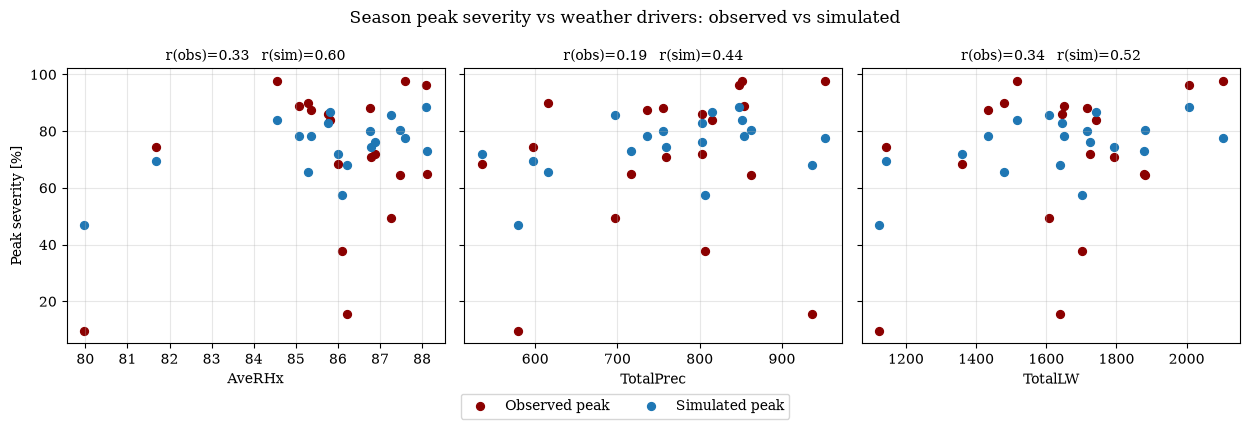

In [26]:
peak_ref = (ref_dis.assign(sow_year=ref_dis["year"] - 1).groupby("sow_year")[FRANCH_DISEASE].max().reindex(dataset.locations))

peak_df = season_summary.set_index("GrowingSeason")[["DiseaseSeverity", "AveRHx", "AveRHn", "TotalPrec", "TotalLW"]].rename(columns={"DiseaseSeverity": "SimulatedPeak"})
peak_df["ObservedPeak"] = peak_ref
peak_df = peak_df.dropna(subset=["ObservedPeak"])
peak_df["PeakError"] = peak_df["SimulatedPeak"] - peak_df["ObservedPeak"]

drivers = ["AveRHx", "TotalPrec", "TotalLW"]
fig, axes = plt.subplots(1, len(drivers), figsize=(4.2 * len(drivers), 4), sharey=True)

for ax, drv in zip(axes, drivers):
    r_obs = np.corrcoef(peak_df[drv], peak_df["ObservedPeak"])[0, 1]
    r_sim = np.corrcoef(peak_df[drv], peak_df["SimulatedPeak"])[0, 1]
    ax.scatter(peak_df[drv], peak_df["ObservedPeak"], color="darkred", s=32, label="Observed peak")
    ax.scatter(peak_df[drv], peak_df["SimulatedPeak"], color="tab:blue", s=32, label="Simulated peak")
    ax.set_xlabel(drv)
    ax.set_title(f"r(obs)={r_obs:.2f}   r(sim)={r_sim:.2f}", fontsize=10)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Peak severity [%]")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Season peak severity vs weather drivers: observed vs simulated", fontsize=12)
fig.tight_layout()
plt.show()


In [27]:
peak_df[["ObservedPeak", "SimulatedPeak", "PeakError"] + drivers].round(2)

,ObservedPeak,SimulatedPeak,PeakError,AveRHx,TotalPrec,TotalLW
GrowingSeason,,,,,,
1972,96.27,88.35,-7.92,88.09,847.3,2006.0
1973,97.77,77.60,-20.17,87.59,952.4,2103.0
1974,64.98,72.87,7.88,88.12,716.9,1878.0
1975,89.98,65.62,-24.36,85.29,615.8,1480.0
1976,74.42,69.48,-4.95,81.68,597.1,1143.0
1977,49.23,85.65,36.43,87.25,697.0,1607.0
1978,70.90,74.45,3.55,86.79,758.4,1792.0
1979,86.10,82.74,-3.37,85.75,802.8,1646.0
1980,97.77,84.05,-13.72,84.56,851.4,1517.0


## 8. Hold-out check

Every result above is calibrated and scored on the same 19 seasons. To see
whether the poorly fitted seasons are a compromise of that joint fit or a
structural limit of the model, recalibrate on 13 seasons only (same starting
values, bounds, trial budget and seed as the best all-seasons run) and score
the 6 held-out seasons. The held-out set mixes well- and poorly-fitted
seasons.

**What this run shows:** on its own 13 seasons the train-only fit scores
13.1, about the same as the all-seasons fit on those seasons (12.7). On the
six held-out seasons it scores 24.6, against 19.2 for the all-seasons fit.
The held-out seasons with the largest errors (1984/85, 1978/79, 1973/74)
cannot be predicted from the others. 1984/85 in particular is off by about 40
points whether or not it is in the training set. These are structural
misfits, not a compromise of the joint fit: see *Why some seasons fit badly*
above.


In [28]:
import copy

HOLDOUT = [1973, 1975, 1978, 1981, 1984, 1988]  # sowing years
ref_train = ref_df[~ref_df["year"].isin([y + 1 for y in HOLDOUT])]

# Same starting values, bounds, trial budget and seed as the best all-seasons run.
ho_cfg = copy.deepcopy(fr_cfg)
ho_cfg.disease_parameters = copy.deepcopy(start_params)
ho_cfg.is_calibration, ho_cfg.n_trials, ho_cfg.seed = True, CALIB_TRIALS, best_run["seed"]

train_session = FranchestynSession(
    ho_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_train,
)
ho_best = train_session.run()
franchestyn.apply_best_params(ho_cfg, ho_best["outputs"]["summary"]["best_params"])

# Score every season with the train-only parameters, on the all-seasons runner.
ho_cfg.is_calibration = False
ho_sim = fr_diagnostics.simulation_frame(
    franchestyn.run_franchestyn(config=ho_cfg, runner=session.runner, **session.inputs))

holdout_table = pd.DataFrame({
    "all_seasons_fit": fr_diagnostics.season_rmse(severity_err),
    "train_only_fit": fr_diagnostics.season_rmse(
        fr_diagnostics.match_ref_to_sim(ho_sim, ref_df, seasons, FRANCH_DISEASE, "DiseaseSeverity")),
})
holdout_table["held_out"] = holdout_table.index.isin(HOLDOUT)
print(holdout_table.groupby("held_out").mean().round(2))
holdout_table.round(1)

- Calibrating 16 using Optuna (TPE), n_trials=1200.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_OuterInoculumShapeParameter']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 50/1200 CURR RMSE=22.3140 BEST RMSE=14.8640

Trial 1200/1200 CURR RMSE=13.8360 BEST RMSE=12.5430
Best RMSE: 12.5430
{'disease_OuterInoculumMax': 0.1977836599890568, 'disease_PathogenSpread': 0.28511149537082564, 'disease_WetnessDurationOptimum': 46.235774643970174, 'disease_WetnessDurationMinimum': 11.451696529084485, 'disease_DryCriticalInterruption': 47.655141766358966, 'disease_Tmin': 5.43270273011506, 'disease_Topt': 19.635479972711163, 'disease_Tmax': 32.20302565576182, 'disease_RelativeHumidityCritical': 56.95606482999133, 'disease_Rain50Detachment': 19.711165963149483, 'disease_RelativeHumidityNotLimiting': 74.03230507111985, 'disease_HydroThermalTimeOnset': 6.654653560413037, 'disease_CyclePercentageOnset': 27.246004460132703, 'disease_LatencyDuration': 24.746111752930968, 'disease_SporulationDuration': 17.549471707766195, 'disease_OuterInoculumShapeParameter': 0.5810601920316338}
          all_seasons_fit  train_only_fit
held_out                                 
False               13.97           12.10
True             

,all_seasons_fit,train_only_fit,held_out
season,,,
1972,12.2,11.9,False
1973,16.8,27.5,True
1974,11.5,4.0,False
1975,12.3,15.7,True
1976,19.6,9.8,False
1977,22.1,18.2,False
1978,19.9,31.8,True
1979,9.5,9.8,False
1980,22.5,10.3,False
